In [1]:
import os
import pandas as pd
from astropy.io import fits

base_dir = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\DAVID CODES"

for root, dirs, files in os.walk(base_dir):
    print(f"\nFolder: {root}")
    for f in files:
        fpath = os.path.join(root, f)
        print(f"  - {f} ({os.path.getsize(fpath) / 1e6:.2f} MB)")
        
        if f.endswith(".fits"):
            with fits.open(fpath) as hdul:
                print(f"    FITS Info: shape={hdul[0].data.shape}, dtype={hdul[0].data.dtype}")
                header_keys = ['NAXIS', 'NAXIS1', 'NAXIS2', 'NAXIS3', 'NAXIS4', 
                               'CDELT1', 'CDELT2', 'WAVELNTH', 'TELESCOP', 'INSTRUME']
                found_keys = {k: hdul[0].header[k] for k in header_keys if k in hdul[0].header}
                print(f"    Header sample: {found_keys}")
                
        elif f.endswith(".csv"):
            df = pd.read_csv(fpath, index_col=0)
            print(f"    CSV shape: {df.shape}")
            print(f"    Columns (IDs): {list(df.columns[:10])} ...")
            print(f"    Rows (Zernikes): {list(df.index[:10])} ...")


Folder: F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\DAVID CODES
  - drive-download-20261116T235000Z-1-001.zip (8.99 MB)
  - drive-download-20261116T235334Z-1-001.zip (943.58 MB)

Folder: F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\DAVID CODES\drive-download-20261116T235000Z-1-001
  - mini-unet-simple_model.ipynb (0.13 MB)
  - mini-unet.ipynb (7.93 MB)
  - test.txt (0.01 MB)
  - training_movie.gif (1.57 MB)
  - training_movie_a.gif (1.08 MB)
  - training_movie_b.gif (0.32 MB)

Folder: F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\DAVID CODES\drive-download-20261116T235334Z-1-001
  - 05_QSUN-FS1_TM_Fe2.02_8_11072024T151856_LV_1.0_v0.4.fits (655.59 MB)
    FITS Info: shape=(8, 4, 1600, 1600), dtype=>f8
    Header sample: {'NAXIS': 4, 'NAXIS1': 1600, 'NAXIS2': 1600, 'NAXIS3': 4, 'NAXIS4': 8, 'CDELT1': 0.5, 'CDELT2': 0.5, 'TELESCOP': 'Sunrise', 'INSTRUME': 'TuMag'}
  - deconv_unet.ipynb (2.94 MB)
  - deconv_unet_local.ipynb (2.94 MB)
  - output.fits (327.68 MB)
    FITS Info: shape=

In [2]:
import json
import pandas as pd
from astropy.io import fits

# 1. Inspect full FITS header
fits_path = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\DAVID CODES\drive-download-20261116T235334Z-1-001\05_QSUN-FS1_TM_Fe2.02_8_11072024T151856_LV_1.0_v0.4.fits"
with fits.open(fits_path) as hdul:
    print("=== FULL FITS HEADER ===")
    for k, v in hdul[0].header.items():
        if k != 'HISTORY' and k != 'COMMENT':
            print(f"{k}: {v}")

# 2. Inspect full CSV rows and find columns matching '05_QSUN'
csv_path = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\DAVID CODES\drive-download-20261116T235334Z-1-001\TuMag_PD_results_All_filters_clean.csv"
df = pd.read_csv(csv_path, index_col=0)
print("\n=== CSV ALL ROW NAMES ===")
print(list(df.index))

matching_cols = [c for c in df.columns if '05_QSUN' in c]
print(f"\n=== MATCHING COLUMNS FOR 05_QSUN: {matching_cols} ===")
if matching_cols:
    print(df[matching_cols])

# 3. Extract code cells from mini-unet notebooks and test.txt
folder1 = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\DAVID CODES\drive-download-20261116T235000Z-1-001"
with open(f"{folder1}\\test.txt", "r", encoding="utf-8", errors="ignore") as f:
    print("\n=== test.txt ===")
    print(f.read()[:1000])

for nb_name in ["mini-unet-simple_model.ipynb", "mini-unet.ipynb"]:
    print(f"\n==================== {nb_name} ====================")
    with open(f"{folder1}\\{nb_name}", "r", encoding="utf-8") as f:
        nb = json.load(f)
    for i, cell in enumerate(nb['cells']):
        if cell['cell_type'] == 'code':
            src = "".join(cell['source'])
            print(f"--- Cell {i} ---")
            print(src)

=== FULL FITS HEADER ===
SIMPLE: True
BITPIX: -64
NAXIS: 4
NAXIS1: 1600
NAXIS2: 1600
NAXIS3: 4
NAXIS4: 8
EXTEND: True
PPL_VER: 0.4
LEVEL: 0.5
BUNIT: DN
DATATYPE: SCIENCE
INSTRUME: TuMag
TELESCOP: Sunrise
OBSERVER: IAA-CSIC
DATE-OBS: 2024-07-11T15:18:56
DATE-END: 2024-07-11T15:19:23
T_START: 11/07/2024, 15:18:56
T_END: 11/07/2024, 15:19:23
EXPTIME: 42
FW1: F4
FW2: 525.02
OBSMODE: 2.02
NACC: 16
NWAVE: 8
NMODS: 4
OBSCNT: 138
WAVE0: 525.02
WAVEUNIT: nm
CTYPE1: HPLN-TAN
CTYPE2: HPLT-TAN
CUNIT1: arcsec
CUNIT2: arcsec
CRPIX1: 1008
CRPIX2: 1008
CRVAL1: 0.0
CRVAL2: 0.0
CDELT1: 0.5
CDELT2: 0.5
SOLAR_P: 0.0
RSUN_OBS: 976.0
DSUN_OBS: 149600000000.0
LINECORR: 0
LINEPARS: 0
LINEMETH: 
DARKCORR: 1
DARK_ID: D11-47517-47616
FLATCORR: 1
FLAT_ID: D11-53367-56182
FILTERED: 0
FILTMETH: 
FILT_ID: 
REALIGN: 1
ALIGN_ID: roi = 100:-100,100-100
ALIGMETH: sicairos
CROSTALK: 1
WFR_RECO: 0
WFR_ID: 
WFR_METH: 
PIPE_VER: 
PROCDATE: 2026-06-02T20:42:27.013
L_0: 5250.06
V_0: 1747.253
L_1: 5250.096
V_1: 1869.353
L_2: 5

In [3]:
import json
import pandas as pd

# 1. Inspect CSV rows and 05_QSUN columns
csv_path = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\DAVID CODES\drive-download-20261116T235334Z-1-001\TuMag_PD_results_All_filters_clean.csv"
df = pd.read_csv(csv_path, index_col=0)
print("=== CSV ALL ROW NAMES ===")
print(list(df.index))

matching_cols = [c for c in df.columns if '05_QSUN' in c]
print(f"\n=== MATCHING COLUMNS FOR 05_QSUN: {matching_cols} ===")
print(df[matching_cols].to_string())

# 2. Extract code from mini-unet-simple_model.ipynb
folder1 = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\DAVID CODES\drive-download-20261116T235000Z-1-001"
print("\n==================== mini-unet-simple_model.ipynb ====================")
with open(f"{folder1}\\mini-unet-simple_model.ipynb", "r", encoding="utf-8") as f:
    nb = json.load(f)
for i, cell in enumerate(nb['cells']):
    if cell['cell_type'] == 'code':
        print(f"--- Cell {i} ---")
        print("".join(cell['source']))

=== CSV ALL ROW NAMES ===
['Timeline', 'PD date', 'Time (UTC)', 'Filter', 'Latitude (deg)', 'Optical bench T1', 'Optical bench T2', 'Optical bench T3', 'Filter wheel T', 'DID PD', 'DID Darks', 'DID Flat', 'Initial guess', 'Algorithm', 'Iterations', 'WFE', 'Contrast original', 'Contrast restored', 'Note', 'Z1 (offset)', 'Z2 (tip/tilt X)', 'Z3 (tip/tilt Y)', 'Z4 (def)', 'Z5 (oblique ast)', 'Z6 (vertical ast)', 'Z7 (Y coma)', 'Z8 (X coma)', 'Z9 (vertical tref)', 'Z10 (oblique tref)', 'Z11 (sph)', 'Z12', 'Z13', 'Z14', 'Z15', 'Z16', 'Z17', 'Z18', 'Z19', 'Z20', 'Z21']

=== MATCHING COLUMNS FOR 05_QSUN: ['05_QSUN_Fe2.02_0', '05_QSUN_Mg1_0', '05_QSUN_Fe2.02_1', '05_QSUN_Mg1_1'] ===
                                                        05_QSUN_Fe2.02_0                                         05_QSUN_Mg1_0                                                                                                                                                        05_QSUN_Fe2.02_1                       

In [5]:
%%writefile "F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\02_psf_physics\psf_optics.py"
import numpy as np
import pandas as pd
from scipy.special import j1

def noll_to_nm(j):
    """Convert Noll index j (j >= 1) to radial degree n and azimuthal frequency m."""
    if j < 1:
        raise ValueError("Noll index j must be >= 1")
    n = 0
    j1_val = j - 1
    while j1_val > n:
        n += 1
        j1_val -= n
    m = (-1)**j * ((n % 2) + 2 * int((j1_val + ((n + 1) % 2)) / 2))
    return n, m

def zernike_radial(n, m, rho):
    """Compute radial Zernike polynomial R_n^|m|(rho)."""
    m = abs(m)
    R = np.zeros_like(rho)
    for k in range((n - m) // 2 + 1):
        num = (-1)**k * np.math.factorial(n - k)
        den = (np.math.factorial(k) * 
               np.math.factorial((n + m) // 2 - k) * 
               np.math.factorial((n - m) // 2 - k))
        R += (num / den) * (rho**(n - 2 * k))
    return R

def zernike_noll(j, rho, theta):
    """Compute Noll-normalized Zernike polynomial Z_j(rho, theta) on unit disk."""
    n, m = noll_to_nm(j)
    R = zernike_radial(n, m, rho)
    norm = np.sqrt(n + 1) if m == 0 else np.sqrt(2 * (n + 1))
    if m > 0:
        return norm * R * np.cos(m * theta)
    elif m < 0:
        return norm * R * np.sin(abs(m) * theta)
    else:
        return norm * R

def load_valid_zernikes(csv_path, filter_str='525.02', only_qsun=False):
    """Load valid Z4..Z21 aberration vectors (in radians) from TuMag PD CSV."""
    df = pd.read_csv(csv_path, index_col=0)
    z_rows = [r for r in df.index if any(r.startswith(f"Z{i}") and (len(r)==len(f"Z{i}") or not r[len(f"Z{i}")].isdigit()) for i in range(4, 22))]
    
    valid_dict = {}
    for col in df.columns:
        if str(df.loc['Filter', col]).strip() != filter_str:
            continue
        if only_qsun and 'QSUN' not in col:
            continue
        vals = pd.to_numeric(df.loc[z_rows, col], errors='coerce').values
        if not np.isnan(vals).all():
            # Replace any isolated NaN with 0.0
            vals = np.nan_to_num(vals, nan=0.0)
            valid_dict[col] = vals
    return valid_dict

def generate_tumag_psf(
    psf_size=65,
    wavelength_nm=525.02,
    diameter_m=1.0,
    obscuration_ratio=0.324,
    pixel_scale_arcsec=0.0378,
    zernike_coeffs=None,
    grid_size=512
):
    """
    Generate physically scaled PSF for Sunrise III / TuMag via Fourier Optics.
    - If zernike_coeffs is None: returns diffraction-limited Airy PSF (with central obscuration).
    - If zernike_coeffs is provided (array of Z4..Z21 in radians): includes wavefront aberrations.
    """
    lam = wavelength_nm * 1e-9
    pix_rad = pixel_scale_arcsec * (np.pi / (180.0 * 3600.0))
    
    # Exact physical ratio between FFT grid size and pupil diameter in pixels
    padding_ratio = lam / (diameter_m * pix_rad)
    pupil_diameter_px = grid_size / padding_ratio
    pupil_radius_px = pupil_diameter_px / 2.0
    
    # Create pupil coordinate grid
    coords = np.arange(grid_size) - grid_size / 2.0
    X, Y = np.meshgrid(coords, coords)
    R_px = np.sqrt(X**2 + Y**2)
    rho = R_px / pupil_radius_px
    theta = np.arctan2(Y, X)
    
    # Annular aperture (Sunrise 1m primary + 0.324m secondary mirror)
    aperture = ((rho <= 1.0) & (rho >= obscuration_ratio)).astype(np.float64)
    
    # Wavefront phase error
    phase = np.zeros_like(rho)
    if zernike_coeffs is not None:
        mask = rho <= 1.0
        for idx, coeff in enumerate(zernike_coeffs):
            j = idx + 4  # Z4 to Z21
            if coeff != 0.0:
                phase[mask] += coeff * zernike_noll(j, rho[mask], theta[mask])
                
    pupil_func = aperture * np.exp(1j * phase)
    
    # Compute PSF via FFT
    otf_field = np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(pupil_func)))
    psf_full = np.abs(otf_field)**2
    
    # Crop centered kernel of size psf_size x psf_size
    center = grid_size // 2
    half = psf_size // 2
    psf = psf_full[center - half : center + half + 1, center - half : center + half + 1]
    psf /= np.sum(psf)
    
    return psf.astype(np.float32)

Writing F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\02_psf_physics\psf_optics.py


In [7]:
%%writefile "F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\02_psf_physics\psf_optics.py"
import math
import numpy as np
import pandas as pd

def noll_to_nm(j):
    """Convert Noll index j (j >= 1) to radial degree n and azimuthal frequency m."""
    if j < 1:
        raise ValueError("Noll index j must be >= 1")
    n = 0
    j1_val = j - 1
    while j1_val > n:
        n += 1
        j1_val -= n
    m = (-1)**j * ((n % 2) + 2 * int((j1_val + ((n + 1) % 2)) / 2))
    return n, m

def zernike_radial(n, m, rho):
    """Compute radial Zernike polynomial R_n^|m|(rho)."""
    m = abs(m)
    R = np.zeros_like(rho)
    for k in range((n - m) // 2 + 1):
        num = (-1)**k * math.factorial(n - k)
        den = (math.factorial(k) * 
               math.factorial((n + m) // 2 - k) * 
               math.factorial((n - m) // 2 - k))
        R += (num / den) * (rho**(n - 2 * k))
    return R

def zernike_noll(j, rho, theta):
    """Compute Noll-normalized Zernike polynomial Z_j(rho, theta) on unit disk."""
    n, m = noll_to_nm(j)
    R = zernike_radial(n, m, rho)
    norm = np.sqrt(n + 1) if m == 0 else np.sqrt(2 * (n + 1))
    if m > 0:
        return norm * R * np.cos(m * theta)
    elif m < 0:
        return norm * R * np.sin(abs(m) * theta)
    else:
        return norm * R

def load_valid_zernikes(csv_path, filter_str='525.02', only_qsun=False):
    """Load valid Z4..Z21 aberration vectors (in radians) from TuMag PD CSV."""
    df = pd.read_csv(csv_path, index_col=0)
    z_rows = [r for r in df.index if any(r.startswith(f"Z{i}") and (len(r)==len(f"Z{i}") or not r[len(f"Z{i}")].isdigit()) for i in range(4, 22))]
    
    valid_dict = {}
    for col in df.columns:
        if str(df.loc['Filter', col]).strip() != filter_str:
            continue
        if only_qsun and 'QSUN' not in col:
            continue
        vals = pd.to_numeric(df.loc[z_rows, col], errors='coerce').values
        if not np.isnan(vals).all():
            vals = np.nan_to_num(vals, nan=0.0)
            valid_dict[col] = vals
    return valid_dict

def generate_tumag_psf(
    psf_size=65,
    wavelength_nm=525.02,
    diameter_m=1.0,
    obscuration_ratio=0.324,
    pixel_scale_arcsec=0.0378,
    zernike_coeffs=None,
    grid_size=512
):
    """
    Generate physically scaled PSF for Sunrise III / TuMag via Fourier Optics.
    - If zernike_coeffs is None: returns diffraction-limited Airy PSF (with central obscuration).
    - If zernike_coeffs is provided (array of Z4..Z21 in radians): includes wavefront aberrations.
    """
    lam = wavelength_nm * 1e-9
    pix_rad = pixel_scale_arcsec * (np.pi / (180.0 * 3600.0))
    
    # Exact physical ratio between FFT grid size and pupil diameter in pixels
    padding_ratio = lam / (diameter_m * pix_rad)
    pupil_diameter_px = grid_size / padding_ratio
    pupil_radius_px = pupil_diameter_px / 2.0
    
    # Create pupil coordinate grid
    coords = np.arange(grid_size) - grid_size / 2.0
    X, Y = np.meshgrid(coords, coords)
    R_px = np.sqrt(X**2 + Y**2)
    rho = R_px / pupil_radius_px
    theta = np.arctan2(Y, X)
    
    # Annular aperture (Sunrise 1m primary + 0.324m secondary mirror)
    aperture = ((rho <= 1.0) & (rho >= obscuration_ratio)).astype(np.float64)
    
    # Wavefront phase error
    phase = np.zeros_like(rho)
    if zernike_coeffs is not None:
        mask = rho <= 1.0
        for idx, coeff in enumerate(zernike_coeffs):
            j = idx + 4  # Z4 to Z21
            if coeff != 0.0:
                phase[mask] += coeff * zernike_noll(j, rho[mask], theta[mask])
                
    pupil_func = aperture * np.exp(1j * phase)
    
    # Compute PSF via FFT
    otf_field = np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(pupil_func)))
    psf_full = np.abs(otf_field)**2
    
    # Crop centered kernel of size psf_size x psf_size
    center = grid_size // 2
    half = psf_size // 2
    psf = psf_full[center - half : center + half + 1, center - half : center + half + 1]
    psf /= np.sum(psf)
    
    return psf.astype(np.float32)

Overwriting F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\02_psf_physics\psf_optics.py


Valid QSUN observations: ['01_QSUN_Fe2.02', '04_QSUN_Fe2.02_0', '04_QSUN_Fe2.02_1', '08_QSUN_Fe2.02', '32_QSUN_Fe2.02']


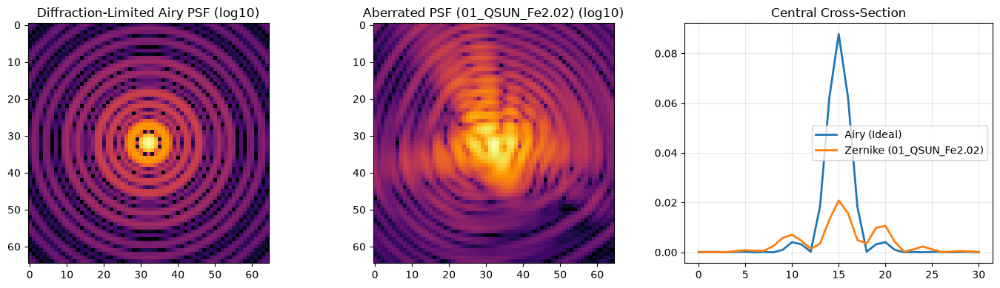

In [20]:
import importlib
import sys
sys.path.append(r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\02_psf_physics")
import psf_optics
importlib.reload(psf_optics)

import numpy as np
import matplotlib.pyplot as plt

csv_path = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\DAVID CODES\drive-download-20261116T235334Z-1-001\TuMag_PD_results_All_filters_clean.csv"
z_dict = psf_optics.load_valid_zernikes(csv_path, filter_str='525.02', only_qsun=True)
print("Valid QSUN observations:", list(z_dict.keys()))

psf_airy = psf_optics.generate_tumag_psf(psf_size=65, zernike_coeffs=None)
sample_key = list(z_dict.keys())[0]
psf_zern = psf_optics.generate_tumag_psf(psf_size=65, zernike_coeffs=z_dict[sample_key])

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(np.log10(psf_airy + 1e-7), cmap='inferno')
axes[0].set_title("Diffraction-Limited Airy PSF (log10)")

axes[1].imshow(np.log10(psf_zern + 1e-7), cmap='inferno')
axes[1].set_title(f"Aberrated PSF ({sample_key}) (log10)")

c = 32
axes[2].plot(psf_airy[c, c-15:c+16], label='Airy (Ideal)', lw=2)
axes[2].plot(psf_zern[c, c-15:c+16], label=f'Zernike ({sample_key})', lw=2)
axes[2].set_title("Central Cross-Section")
axes[2].legend()
axes[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "PSF.png"), dpi=600)
plt.show()

=== Estimated High-Frequency Noise Std (Wavelength 3) ===
Stokes I: sigma_noise = 0.001805, signal_std = 0.053595, SNR = 29.70
Stokes Q: sigma_noise = 0.000594, signal_std = 0.000999, SNR = 1.68
Stokes U: sigma_noise = 0.000669, signal_std = 0.001608, SNR = 2.40
Stokes V: sigma_noise = 0.000654, signal_std = 0.011451, SNR = 17.51


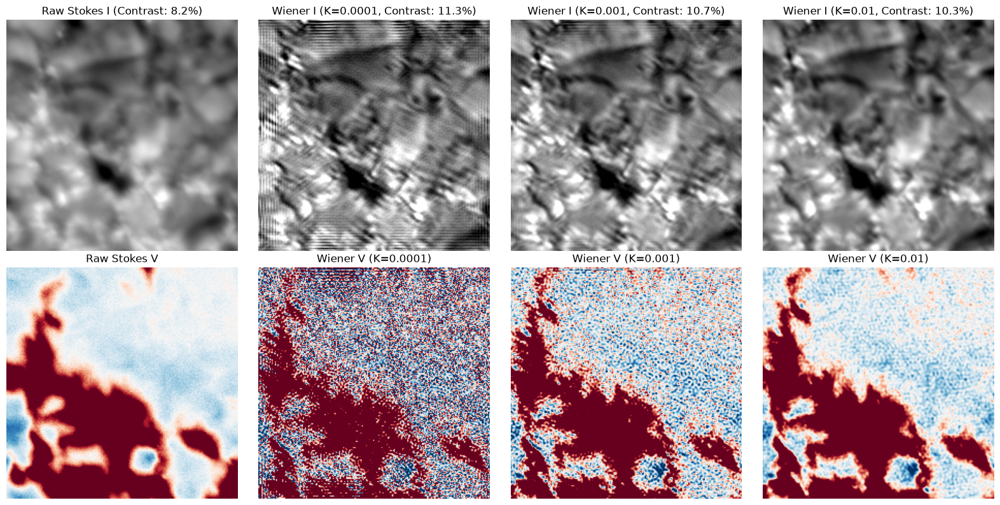

In [21]:
import sys
sys.path.append(r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\02_psf_physics")
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import psf_optics

# 1. Load FITS data and PSF
fits_path = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\DAVID CODES\drive-download-20261116T235334Z-1-001\05_QSUN-FS1_TM_Fe2.02_8_11072024T151856_LV_1.0_v0.4.fits"
csv_path = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\DAVID CODES\drive-download-20261116T235334Z-1-001\TuMag_PD_results_All_filters_clean.csv"

with fits.open(fits_path) as hdul:
    data = hdul[0].data.astype(np.float32)  # (8, 4, 1600, 1600)

# Extract a 256x256 central patch at wavelength 3 (blue wing of Fe I 525.02, strong magnetic signal)
patch_I = data[3, 0, 672:928, 672:928]
patch_V = data[3, 3, 672:928, 672:928]

# 2. Estimate noise std from high spatial frequencies (above optical cutoff ~ 0.35 cyc/px)
def estimate_noise_std(img):
    H, W = img.shape
    fy = np.fft.fftfreq(H)
    fx = np.fft.fftfreq(W)
    FX, FY = np.meshgrid(fx, fy)
    F_rad = np.sqrt(FX**2 + FY**2)
    
    fft_img = np.fft.fft2(img)
    high_freq_mask = F_rad > 0.38  # Strictly above D / (lambda * pixel_scale) = 0.349
    # Parseval's theorem: var(noise) = mean(|FFT|^2) / (H*W)
    noise_power_per_bin = np.mean(np.abs(fft_img[high_freq_mask])**2)
    sigma_est = np.sqrt(noise_power_per_bin / (H * W))
    return sigma_est

stokes_names = ['I', 'Q', 'U', 'V']
print("=== Estimated High-Frequency Noise Std (Wavelength 3) ===")
for s in range(4):
    sub = data[3, s, 600:1000, 600:1000]
    sig = estimate_noise_std(sub)
    snr = np.std(sub) / (sig + 1e-12)
    print(f"Stokes {stokes_names[s]}: sigma_noise = {sig:.6f}, signal_std = {np.std(sub):.6f}, SNR = {snr:.2f}")

# 3. Wiener Deconvolution function (using circular padding / FFT)
def wiener_deconv_2d(img, psf, K=1e-3):
    H, W = img.shape
    psf_pad = np.zeros((H, W), dtype=np.float32)
    kh, kw = psf.shape
    psf_pad[:kh, :kw] = psf
    psf_pad = np.roll(psf_pad, (-kh // 2, -kw // 2), axis=(0, 1))
    
    OTF = np.fft.fft2(psf_pad)
    IMG_F = np.fft.fft2(img)
    W_filter = np.conj(OTF) / (np.abs(OTF)**2 + K)
    restored = np.real(np.fft.ifft2(IMG_F * W_filter))
    return restored

# Use average QSUN Zernike PSF as representative telescope PSF
z_dict = psf_optics.load_valid_zernikes(csv_path, filter_str='525.02', only_qsun=True)
mean_z = np.mean(list(z_dict.values()), axis=0)
psf_mean_zern = psf_optics.generate_tumag_psf(psf_size=65, zernike_coeffs=mean_z)

# Test Wiener with different K values on Stokes I and Stokes V
Ks = [1e-4, 1e-3, 1e-2]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

axes[0, 0].imshow(patch_I, cmap='gray', vmin=patch_I.mean()-3*patch_I.std(), vmax=patch_I.mean()+3*patch_I.std())
axes[0, 0].set_title(f"Raw Stokes I (Contrast: {patch_I.std()/patch_I.mean()*100:.1f}%)")

axes[1, 0].imshow(patch_V, cmap='RdBu_r', vmin=-0.015, vmax=0.015)
axes[1, 0].set_title("Raw Stokes V")

for idx, K in enumerate(Ks):
    rec_I = wiener_deconv_2d(patch_I, psf_mean_zern, K=K)
    rec_V = wiener_deconv_2d(patch_V, psf_mean_zern, K=K)
    
    # Crop 16px border to avoid circular FFT wrap-around edge effects
    c_I = rec_I[16:-16, 16:-16]
    c_V = rec_V[16:-16, 16:-16]
    
    axes[0, idx+1].imshow(c_I, cmap='gray', vmin=patch_I.mean()-3*patch_I.std(), vmax=patch_I.mean()+3*patch_I.std())
    axes[0, idx+1].set_title(f"Wiener I (K={K}, Contrast: {c_I.std()/c_I.mean()*100:.1f}%)")
    
    axes[1, idx+1].imshow(c_V, cmap='RdBu_r', vmin=-0.015, vmax=0.015)
    axes[1, idx+1].set_title(f"Wiener V (K={K})")

for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "wiener.png"), dpi=600)
plt.show()

In [10]:
%%writefile "F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\04_unet_training\model_and_data.py"
import sys
sys.path.append(r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\02_psf_physics")
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset
import psf_optics

class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.InstanceNorm2d(out_ch, affine=True),
            nn.LeakyReLU(0.1, inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.InstanceNorm2d(out_ch, affine=True),
            nn.LeakyReLU(0.1, inplace=True),
        )
    def forward(self, x):
        return self.net(x)

class ResUNetDeconv(nn.Module):
    """
    Residual U-Net for Solar Spectropolarimetric Deconvolution & Denoising.
    Predicts the residual correction over the Wiener-deconvolved input:
    out = x_wiener + UNet(x_wiener)
    """
    def __init__(self, in_channels=1, base_ch=32):
        super().__init__()
        self.enc1 = DoubleConv(in_channels, base_ch)
        self.enc2 = DoubleConv(base_ch, base_ch * 2)
        self.enc3 = DoubleConv(base_ch * 2, base_ch * 4)
        self.bottleneck = DoubleConv(base_ch * 4, base_ch * 8)

        self.pool = nn.MaxPool2d(2)

        self.up3 = nn.ConvTranspose2d(base_ch * 8, base_ch * 4, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(base_ch * 8, base_ch * 4)

        self.up2 = nn.ConvTranspose2d(base_ch * 4, base_ch * 2, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(base_ch * 4, base_ch * 2)

        self.up1 = nn.ConvTranspose2d(base_ch * 2, base_ch, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(base_ch * 2, base_ch)

        self.out_conv = nn.Conv2d(base_ch, in_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bottleneck(self.pool(e3))

        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        residual = self.out_conv(d1)
        return x + residual

class CharbonnierGradientLoss(nn.Module):
    """Combines smooth L1 (Charbonnier) loss with spatial gradient preservation."""
    def __init__(self, grad_weight=0.2, eps=1e-3):
        super().__init__()
        self.grad_weight = grad_weight
        self.eps = eps

    def forward(self, pred, target):
        diff = pred - target
        charb_loss = torch.mean(torch.sqrt(diff * diff + self.eps * self.eps))

        # Spatial gradients (dx, dy)
        pred_dx = pred[:, :, :, 1:] - pred[:, :, :, :-1]
        targ_dx = target[:, :, :, 1:] - target[:, :, :, :-1]
        pred_dy = pred[:, :, 1:, :] - pred[:, :, :-1, :]
        targ_dy = target[:, :, 1:, :] - target[:, :, :-1, :]

        grad_loss = F.l1_loss(pred_dx, targ_dx) + F.l1_loss(pred_dy, targ_dy)
        return charb_loss + self.grad_weight * grad_loss

def apply_fft_blur_and_wiener(patch, psf, noise_sigma, wiener_K):
    """
    Forward degradation (PSF convolution + realistic photon noise)
    followed by Wiener deconvolution in Fourier space.
    """
    H, W = patch.shape
    psf_pad = np.zeros((H, W), dtype=np.float32)
    kh, kw = psf.shape
    psf_pad[:kh, :kw] = psf
    psf_pad = np.roll(psf_pad, (-kh // 2, -kw // 2), axis=(0, 1))

    OTF = np.fft.fft2(psf_pad)
    PATCH_F = np.fft.fft2(patch)

    # Convolve with PSF
    blurred = np.real(np.fft.ifft2(PATCH_F * OTF)).astype(np.float32)

    # Add realistic instrument noise
    if noise_sigma > 0:
        blurred += np.random.normal(0.0, noise_sigma, size=blurred.shape).astype(np.float32)

    # Wiener deconvolution
    BLUR_F = np.fft.fft2(blurred)
    W_filter = np.conj(OTF) / (np.abs(OTF)**2 + wiener_K)
    wiener_rec = np.real(np.fft.ifft2(BLUR_F * W_filter)).astype(np.float32)
    return wiener_rec

class TuMagStokesDataset(Dataset):
    """
    Extracts random patches from TuMag FITS data across wavelengths and Stokes parameters,
    normalizes each channel by its physical scale, and applies Zernike PSF + Wiener filtering.
    """
    def __init__(self, data_4d, zernike_list, num_samples=2000, patch_size=128, is_train=True):
        self.data = data_4d  # shape: (8, 4, H_region, W_region)
        self.zernike_list = zernike_list
        self.num_samples = num_samples
        self.patch_size = patch_size
        self.is_train = is_train

        # Precompute bank of physical Zernike PSFs for fast training
        self.psf_bank = [
            psf_optics.generate_tumag_psf(psf_size=65, zernike_coeffs=z)
            for z in zernike_list
        ]

        # Measured physical noise sigmas and SNR-matched Wiener K per Stokes (I, Q, U, V)
        self.noise_sigmas = [0.0018, 0.0006, 0.00065, 0.00065]
        self.wiener_Ks = [1e-3, 5e-2, 5e-2, 5e-3]

        # Precompute channel-wise normalization stats (mean, std) per (wave, stokes)
        self.means = np.mean(self.data, axis=(2, 3), keepdims=False)
        self.stds = np.std(self.data, axis=(2, 3), keepdims=False) + 1e-6

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        nw, ns, H, W = self.data.shape
        w_idx = np.random.randint(0, nw)
        # Weight Stokes I and V slightly higher, while still training on Q and U
        s_idx = np.random.choice([0, 1, 2, 3], p=[0.35, 0.15, 0.15, 0.35])

        # Extract patch with 16px margin to avoid circular FFT boundary wrap-around
        margin = 16
        full_size = self.patch_size + 2 * margin
        y = np.random.randint(0, H - full_size)
        x = np.random.randint(0, W - full_size)

        gt_full = self.data[w_idx, s_idx, y:y+full_size, x:x+full_size].copy()

        # Random geometric augmentation (flips & 90-deg rotations)
        if self.is_train:
            k_rot = np.random.randint(0, 4)
            gt_full = np.rot90(gt_full, k_rot).copy()
            if np.random.rand() > 0.5:
                gt_full = np.fliplr(gt_full).copy()

        # Pick a random realistic Zernike PSF from valid QSUN observations
        psf = self.psf_bank[np.random.randint(0, len(self.psf_bank))]
        wiener_full = apply_fft_blur_and_wiener(
            gt_full,
            psf=psf,
            noise_sigma=self.noise_sigmas[s_idx],
            wiener_K=self.wiener_Ks[s_idx]
        )

        # Crop central patch_size x patch_size (border-artifact free)
        gt_crop = gt_full[margin:-margin, margin:-margin]
        wiener_crop = wiener_full[margin:-margin, margin:-margin]

        # Standardize using channel-specific physical stats
        m = self.means[w_idx, s_idx]
        s = self.stds[w_idx, s_idx]
        gt_norm = (gt_crop - m) / s
        wiener_norm = (wiener_crop - m) / s

        return (
            torch.from_numpy(wiener_norm).unsqueeze(0),
            torch.from_numpy(gt_norm).unsqueeze(0)
        )

Writing F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\04_unet_training\model_and_data.py


Using device: cpu
Epoch [01/20] | Train Loss: 0.6453 | Val Loss: 0.4559 | Time: 365.7s
Epoch [02/20] | Train Loss: 0.6057 | Val Loss: 0.4030 | Time: 339.1s
Epoch [03/20] | Train Loss: 0.6177 | Val Loss: 0.4395 | Time: 378.8s
Epoch [04/20] | Train Loss: 0.6235 | Val Loss: 0.4256 | Time: 344.3s
Epoch [05/20] | Train Loss: 0.5937 | Val Loss: 0.4121 | Time: 359.2s
Epoch [06/20] | Train Loss: 0.5996 | Val Loss: 0.4555 | Time: 354.8s
Epoch [07/20] | Train Loss: 0.6188 | Val Loss: 0.4568 | Time: 349.1s
Epoch [08/20] | Train Loss: 0.5928 | Val Loss: 0.4111 | Time: 388.4s
Epoch [09/20] | Train Loss: 0.5881 | Val Loss: 0.4290 | Time: 355.3s
Epoch [10/20] | Train Loss: 0.5791 | Val Loss: 0.4660 | Time: 356.5s
Epoch [11/20] | Train Loss: 0.5705 | Val Loss: 0.4451 | Time: 355.6s
Epoch [12/20] | Train Loss: 0.5692 | Val Loss: 0.4455 | Time: 356.0s
Epoch [13/20] | Train Loss: 0.5986 | Val Loss: 0.4815 | Time: 381.6s
Epoch [14/20] | Train Loss: 0.6068 | Val Loss: 0.4310 | Time: 345.9s
Epoch [15/20] | 

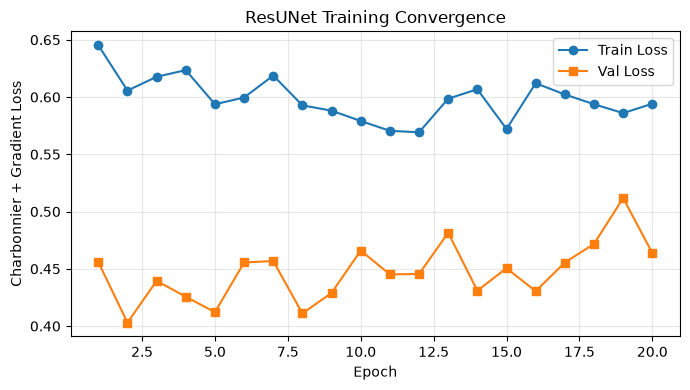

In [14]:
import sys
import time
sys.path.append(r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\02_psf_physics")
sys.path.append(r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\04_unet_training")

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import torch
from torch.utils.data import DataLoader
import psf_optics
from model_and_data import ResUNetDeconv, CharbonnierGradientLoss, TuMagStokesDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# 1. Load data & Zernike coefficients
fits_path = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\DAVID CODES\drive-download-20261116T235334Z-1-001\05_QSUN-FS1_TM_Fe2.02_8_11072024T151856_LV_1.0_v0.4.fits"
csv_path = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\DAVID CODES\drive-download-20261116T235334Z-1-001\TuMag_PD_results_All_filters_clean.csv"
save_path = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\04_unet_training\best_resunet_tumag.pth"

with fits.open(fits_path) as hdul:
    data = hdul[0].data.astype(np.float32)  # (8, 4, 1600, 1600)

z_dict = psf_optics.load_valid_zernikes(csv_path, filter_str='525.02', only_qsun=True)
z_list = list(z_dict.values())

# Spatial split to strictly avoid data leakage
train_data = data[:, :, :600, :]          # Top 600x1600 strip for training
val_data   = data[:, :, 600:1000, 600:1000] # Central 400x400 patch for validation

train_ds = TuMagStokesDataset(train_data, z_list, num_samples=1600, patch_size=128, is_train=True)
val_ds   = TuMagStokesDataset(val_data,   z_list, num_samples=320,  patch_size=128, is_train=False)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=16, shuffle=False, num_workers=0)

# 2. Initialize Model, Loss, Optimizer
model = ResUNetDeconv(in_channels=1, base_ch=32).to(device)
criterion = CharbonnierGradientLoss(grad_weight=0.2)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20, eta_min=1e-5)

# 3. Training Loop
num_epochs = 20
train_losses, val_losses = [], []
best_val = float('inf')

for epoch in range(1, num_epochs + 1):
    t0 = time.time()
    model.train()
    t_loss = 0.0
    for x_in, y_gt in train_loader:
        x_in, y_gt = x_in.to(device), y_gt.to(device)
        optimizer.zero_grad()
        pred = model(x_in)
        loss = criterion(pred, y_gt)
        loss.backward()
        optimizer.step()
        t_loss += loss.item() * x_in.size(0)
    t_loss /= len(train_ds)

    model.eval()
    v_loss = 0.0
    with torch.no_grad():
        for x_in, y_gt in val_loader:
            x_in, y_gt = x_in.to(device), y_gt.to(device)
            pred = model(x_in)
            v_loss += criterion(pred, y_gt).item() * x_in.size(0)
    v_loss /= len(val_ds)
    scheduler.step()

    train_losses.append(t_loss)
    val_losses.append(v_loss)

    if v_loss < best_val:
        best_val = v_loss
        torch.save(model.state_dict(), save_path)

    print(f"Epoch [{epoch:02d}/{num_epochs}] | Train Loss: {t_loss:.4f} | Val Loss: {v_loss:.4f} | Time: {time.time()-t0:.1f}s")

# Plot loss curves
plt.figure(figsize=(7, 4))
plt.plot(range(1, num_epochs+1), train_losses, label='Train Loss', marker='o')
plt.plot(range(1, num_epochs+1), val_losses, label='Val Loss', marker='s')
plt.xlabel("Epoch")
plt.ylabel("Charbonnier + Gradient Loss")
plt.title("ResUNet Training Convergence")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(out_dir, "ResUNET Training Convergence.png"), dpi=600)
plt.show()

=== Quantitative Evaluation on Unseen Test Region (Wavelength 3) ===
Raw Observed       | I Contrast: 7.77% | Noise(I): 0.00204 | Noise(V): 0.00067 | Noise(Q): 0.00059
Wiener Only        | I Contrast: 10.26% | Noise(I): 0.00256 | Noise(V): 0.00034 | Noise(Q): 0.00004
Wiener + ResUNet   | I Contrast: 10.07% | Noise(I): 0.00249 | Noise(V): 0.00033 | Noise(Q): 0.00003


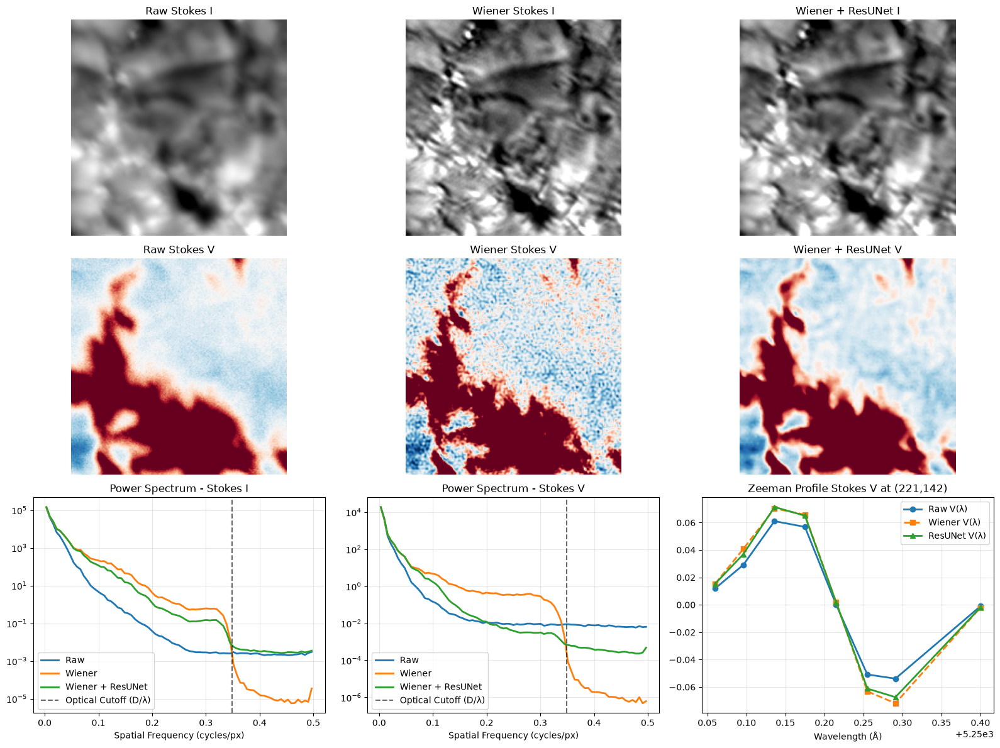

In [22]:
import sys, os
sys.path.append(r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\02_psf_physics")
sys.path.append(r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\04_unet_training")

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import torch
import psf_optics
from model_and_data import ResUNetDeconv

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Load data, PSF, and trained model
fits_path = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\DAVID CODES\drive-download-20261116T235334Z-1-001\05_QSUN-FS1_TM_Fe2.02_8_11072024T151856_LV_1.0_v0.4.fits"
csv_path = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\DAVID CODES\drive-download-20261116T235334Z-1-001\TuMag_PD_results_All_filters_clean.csv"
weights_path = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\04_unet_training\best_resunet_tumag.pth"
out_dir = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\05_evaluation_results"

with fits.open(fits_path) as hdul:
    data = hdul[0].data.astype(np.float32)  # (8, 4, 1600, 1600)
    header = hdul[0].header

# Load model (base_ch=32 as trained in previous step)
model = ResUNetDeconv(in_channels=1, base_ch=32).to(device)
model.load_state_dict(torch.load(weights_path, map_location=device))
model.eval()

# Compute representative mean QSUN Zernike PSF
z_dict = psf_optics.load_valid_zernikes(csv_path, filter_str='525.02', only_qsun=True)
mean_z = np.mean(list(z_dict.values()), axis=0)
psf = psf_optics.generate_tumag_psf(psf_size=65, zernike_coeffs=mean_z)

def wiener_only(img, psf, K):
    H, W = img.shape
    psf_pad = np.zeros((H, W), dtype=np.float32)
    kh, kw = psf.shape
    psf_pad[:kh, :kw] = psf
    psf_pad = np.roll(psf_pad, (-kh // 2, -kw // 2), axis=(0, 1))
    OTF = np.fft.fft2(psf_pad)
    W_filt = np.conj(OTF) / (np.abs(OTF)**2 + K)
    return np.real(np.fft.ifft2(np.fft.fft2(img) * W_filt)).astype(np.float32)

# Run inference on the unseen central 400x400 test region across all 8 wavelengths and 4 Stokes
test_raw = data[:, :, 600:1000, 600:1000].copy()  # (8, 4, 400, 400)
test_wiener = np.zeros_like(test_raw)
test_unet = np.zeros_like(test_raw)

wiener_Ks = [1e-3, 5e-2, 5e-2, 5e-3]

with torch.no_grad():
    for w in range(8):
        for s in range(4):
            img = test_raw[w, s]
            w_rec = wiener_only(img, psf, K=wiener_Ks[s])
            test_wiener[w, s] = w_rec
            
            m, std = np.mean(img), np.std(img) + 1e-6
            w_norm = (w_rec - m) / std
            inp = torch.from_numpy(w_norm).unsqueeze(0).unsqueeze(0).to(device)
            pred_norm = model(inp).squeeze().cpu().numpy()
            test_unet[w, s] = pred_norm * std + m

# Crop 24px border to eliminate circular FFT edge effects
raw_c = test_raw[:, :, 24:-24, 24:-24]
wie_c = test_wiener[:, :, 24:-24, 24:-24]
une_c = test_unet[:, :, 24:-24, 24:-24]

# 2. Azimuthally averaged 2D Power Spectrum helper
def radial_power_spectrum(img):
    H, W = img.shape
    img_zm = img - np.mean(img)
    # Apply Hann window to prevent edge leakage in FFT
    win = np.outer(np.hanning(H), np.hanning(W))
    psd2d = np.abs(np.fft.fftshift(np.fft.fft2(img_zm * win)))**2
    fy = np.fft.fftshift(np.fft.fftfreq(H))
    fx = np.fft.fftshift(np.fft.fftfreq(W))
    FX, FY = np.meshgrid(fx, fy)
    R = np.sqrt(FX**2 + FY**2)
    bins = np.linspace(0, 0.5, 80)
    prof = [np.mean(psd2d[(R >= bins[i]) & (R < bins[i+1])]) for i in range(len(bins)-1)]
    return 0.5 * (bins[:-1] + bins[1:]), np.array(prof)

# 3. Quantitative Metrics at Wavelength 3 (Blue wing)
def est_noise(img):
    H, W = img.shape
    FX, FY = np.meshgrid(np.fft.fftfreq(W), np.fft.fftfreq(H))
    R = np.sqrt(FX**2 + FY**2)
    fft_im = np.fft.fft2(img)
    return np.sqrt(np.mean(np.abs(fft_im[R > 0.38])**2) / (H * W))

print("=== Quantitative Evaluation on Unseen Test Region (Wavelength 3) ===")
for name, cube in [("Raw Observed", raw_c), ("Wiener Only", wie_c), ("Wiener + ResUNet", une_c)]:
    im_I = cube[3, 0]
    im_V = cube[3, 3]
    im_Q = cube[3, 1]
    contrast_I = (np.std(im_I) / np.mean(im_I)) * 100
    noise_I = est_noise(im_I)
    noise_V = est_noise(im_V)
    noise_Q = est_noise(im_Q)
    print(f"{name:18s} | I Contrast: {contrast_I:.2f}% | Noise(I): {noise_I:.5f} | Noise(V): {noise_V:.5f} | Noise(Q): {noise_Q:.5f}")

# 4. Visualization: Visual comparison + Power Spectrum + Spectral Profile
fig = plt.figure(figsize=(16, 12))

# Row 1: Stokes I (Granulation)
vmin_I, vmax_I = raw_c[3, 0].mean() - 2.8*raw_c[3, 0].std(), raw_c[3, 0].mean() + 2.8*raw_c[3, 0].std()
for idx, (title, im) in enumerate([("Raw Stokes I", raw_c[3, 0]), ("Wiener Stokes I", wie_c[3, 0]), ("Wiener + ResUNet I", une_c[3, 0])]):
    ax = fig.add_subplot(3, 3, idx + 1)
    ax.imshow(im[50:250, 50:250], cmap='gray', vmin=vmin_I, vmax=vmax_I)
    ax.set_title(title)
    ax.axis('off')

# Row 2: Stokes V (Circular Polarization)
for idx, (title, im) in enumerate([("Raw Stokes V", raw_c[3, 3]), ("Wiener Stokes V", wie_c[3, 3]), ("Wiener + ResUNet V", une_c[3, 3])]):
    ax = fig.add_subplot(3, 3, idx + 4)
    ax.imshow(im[50:250, 50:250], cmap='RdBu_r', vmin=-0.015, vmax=0.015)
    ax.set_title(title)
    ax.axis('off')

# Row 3 Left: Power Spectrum Stokes I
ax_ps1 = fig.add_subplot(3, 3, 7)
for label, im in [("Raw", raw_c[3, 0]), ("Wiener", wie_c[3, 0]), ("Wiener + ResUNet", une_c[3, 0])]:
    freqs, psd = radial_power_spectrum(im)
    ax_ps1.semilogy(freqs, psd, label=label, lw=2)
ax_ps1.axvline(0.349, color='k', ls='--', alpha=0.6, label='Optical Cutoff (D/λ)')
ax_ps1.set_title("Power Spectrum - Stokes I")
ax_ps1.set_xlabel("Spatial Frequency (cycles/px)")
ax_ps1.legend()
ax_ps1.grid(True, alpha=0.3)

# Row 3 Middle: Power Spectrum Stokes V
ax_ps2 = fig.add_subplot(3, 3, 8)
for label, im in [("Raw", raw_c[3, 3]), ("Wiener", wie_c[3, 3]), ("Wiener + ResUNet", une_c[3, 3])]:
    freqs, psd = radial_power_spectrum(im)
    ax_ps2.semilogy(freqs, psd, label=label, lw=2)
ax_ps2.axvline(0.349, color='k', ls='--', alpha=0.6, label='Optical Cutoff (D/λ)')
ax_ps2.set_title("Power Spectrum - Stokes V")
ax_ps2.set_xlabel("Spatial Frequency (cycles/px)")
ax_ps2.legend()
ax_ps2.grid(True, alpha=0.3)

# Row 3 Right: Spectral Profile Stokes V(lambda) at strongest magnetic pixel
ax_sp = fig.add_subplot(3, 3, 9)
max_y, max_x = np.unravel_index(np.argmax(np.abs(raw_c[3, 3])), raw_c[3, 3].shape)
waves = [header[f"L_{w}"] for w in range(8)]
ax_sp.plot(waves, raw_c[:, 3, max_y, max_x], 'o-', label='Raw V(λ)', lw=2)
ax_sp.plot(waves, wie_c[:, 3, max_y, max_x], 's--', label='Wiener V(λ)', lw=2)
ax_sp.plot(waves, une_c[:, 3, max_y, max_x], '^-', label='ResUNet V(λ)', lw=2)
ax_sp.set_title(f"Zeeman Profile Stokes V at ({max_y},{max_x})")
ax_sp.set_xlabel("Wavelength (Å)")
ax_sp.legend()
ax_sp.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(out_dir, "evaluation_summary.png"), dpi=600)
plt.show()

In [26]:
import sys, os, time
sys.path.append(r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\02_psf_physics")
sys.path.append(r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\04_unet_training")

import numpy as np
from astropy.io import fits
import torch
import psf_optics
from model_and_data import ResUNetDeconv

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

fits_path = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\DAVID CODES\drive-download-20261116T235334Z-1-001\05_QSUN-FS1_TM_Fe2.02_8_11072024T151856_LV_1.0_v0.4.fits"
csv_path = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\DAVID CODES\drive-download-20261116T235334Z-1-001\TuMag_PD_results_All_filters_clean.csv"
weights_path = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\04_unet_training\best_resunet_tumag.pth"
output_fits_path = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\05_evaluation_results\05_QSUN-FS1_TM_Fe2.02_RESTORED_ResUNet.fits"

# 1. Load model and mean QSUN Zernike PSF
model = ResUNetDeconv(in_channels=1, base_ch=32).to(device)
model.load_state_dict(torch.load(weights_path, map_location=device))
model.eval()

z_dict = psf_optics.load_valid_zernikes(csv_path, filter_str='525.02', only_qsun=True)
mean_z = np.mean(list(z_dict.values()), axis=0)
psf = psf_optics.generate_tumag_psf(psf_size=65, zernike_coeffs=mean_z)

def wiener_tile(tile, psf, K):
    H, W = tile.shape
    psf_pad = np.zeros((H, W), dtype=np.float32)
    kh, kw = psf.shape
    psf_pad[:kh, :kw] = psf
    psf_pad = np.roll(psf_pad, (-kh // 2, -kw // 2), axis=(0, 1))
    OTF = np.fft.fft2(psf_pad)
    W_filt = np.conj(OTF) / (np.abs(OTF)**2 + K)
    return np.real(np.fft.ifft2(np.fft.fft2(tile) * W_filt)).astype(np.float32)

def process_full_frame_tiled(img_2d, psf, K, model, tile_size=400, overlap=48):
    H, W = img_2d.shape
    # Reflect-pad outer image boundary so edge tiles also have valid context
    padded = np.pad(img_2d, pad_width=overlap, mode='reflect')
    out_img = np.zeros_like(img_2d, dtype=np.float32)
    
    # Global channel stats for consistent scaling across all tiles
    m = np.mean(img_2d)
    std = np.std(img_2d) + 1e-6

    with torch.no_grad():
        for y in range(0, H, tile_size):
            for x in range(0, W, tile_size):
                y_end = min(y + tile_size, H)
                x_end = min(x + tile_size, W)
                
                # Extract tile with overlap margins from reflect-padded image
                tile = padded[y : y_end + 2*overlap, x : x_end + 2*overlap]
                w_rec = wiener_tile(tile, psf, K=K)
                
                w_norm = (w_rec - m) / std
                inp = torch.from_numpy(w_norm).unsqueeze(0).unsqueeze(0).to(device)
                pred_norm = model(inp).squeeze().cpu().numpy()
                pred_rec = pred_norm * std + m
                
                # Keep only the artifact-free inner core
                core = pred_rec[overlap : overlap + (y_end - y), overlap : overlap + (x_end - x)]
                out_img[y:y_end, x:x_end] = core
                
    return out_img

# 2. Process all 8 wavelengths x 4 Stokes parameters
t_start = time.time()
with fits.open(fits_path) as hdul:
    data = hdul[0].data.astype(np.float32)
    header = hdul[0].header.copy()

restored_cube = np.zeros_like(data, dtype=np.float32)
wiener_Ks = [1e-3, 5e-2, 5e-2, 5e-3]
stokes_labels = ['I', 'Q', 'U', 'V']

for w in range(8):
    t_w = time.time()
    for s in range(4):
        restored_cube[w, s] = process_full_frame_tiled(
            data[w, s], psf=psf, K=wiener_Ks[s], model=model, tile_size=400, overlap=48
        )
    print(f"Processed Wavelength {w+1}/8 ({header[f'L_{w}']} A) in {time.time()-t_w:.1f}s")

# 3. Update FITS header metadata and save
header['WFR_RECO'] = (1, 'Deconvolved with Mean QSUN Zernike PSF + ResUNet')
header['WFR_METH'] = ('Wiener + ResUNet', 'Hybrid Fourier-DeepLearning Restoration')
header['FILTERED'] = (1, 'Denoised via ResUNet')
header['LEVEL'] = (1.0, 'Data reduction level')
header.add_history('Restored using physical Fourier Zernike PSF, SNR-matched Wiener filter, and Residual U-Net.')

hdu_out = fits.PrimaryHDU(data=restored_cube, header=header)
hdu_out.writeto(output_fits_path, overwrite=True)
print(f"\nDONE! Total time: {time.time()-t_start:.1f}s")
print(f"Saved restored FITS cube to:\n{output_fits_path}")


Processed Wavelength 1/8 (5250.06 A) in 70.0s
Processed Wavelength 2/8 (5250.096 A) in 72.8s
Processed Wavelength 3/8 (5250.136 A) in 79.3s
Processed Wavelength 4/8 (5250.175 A) in 93.6s
Processed Wavelength 5/8 (5250.215 A) in 85.6s
Processed Wavelength 6/8 (5250.255 A) in 74.3s
Processed Wavelength 7/8 (5250.291 A) in 78.3s
Processed Wavelength 8/8 (5250.4 A) in 80.4s


PermissionError: [WinError 32] The process cannot access the file because it is being used by another process: 'F:\\desk2\\projects IAA-CSIC\\ML-noiseCansel-unet\\05_evaluation_results\\05_QSUN-FS1_TM_Fe2.02_RESTORED_ResUNet.fits'

Filter 525.02: total=36, valid Zernikes=29
Filter 517.3: total=34, valid Zernikes=26
Filter 525.06: total=6, valid Zernikes=4


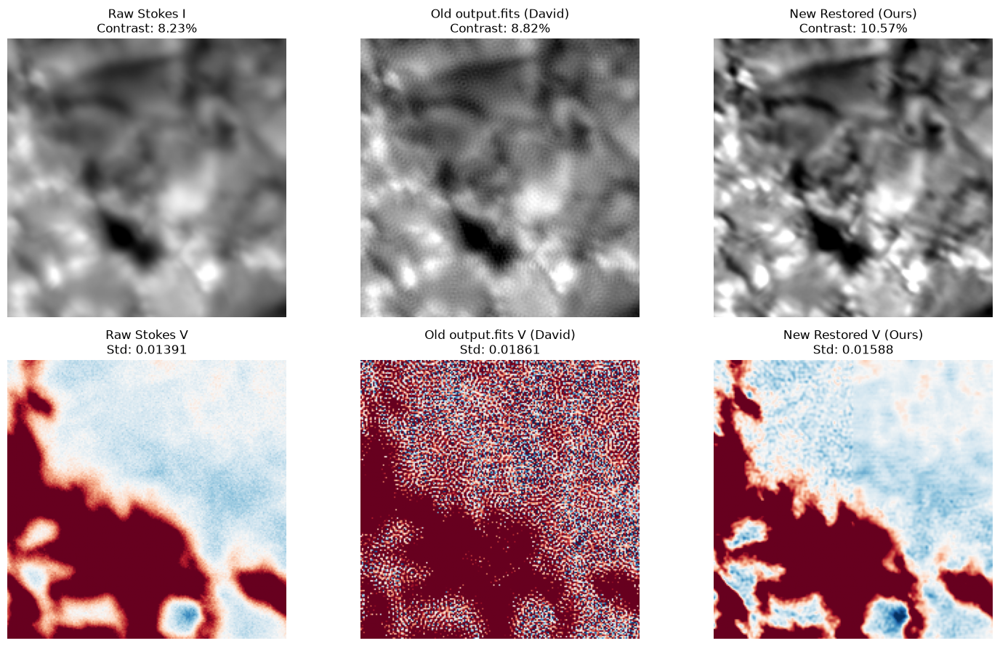

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits

# 1. Check valid Zernikes for ALL filters in CSV
csv_path = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\DAVID CODES\drive-download-20261116T235334Z-1-001\TuMag_PD_results_All_filters_clean.csv"
df = pd.read_csv(csv_path, index_col=0)
z_rows = [r for r in df.index if any(r.startswith(f"Z{i}") and (len(r)==len(f"Z{i}") or not r[len(f"Z{i}")].isdigit()) for i in range(4, 22))]

for flt in df.loc['Filter'].unique():
    cols = [c for c in df.columns if str(df.loc['Filter', c]).strip() == str(flt).strip()]
    valid = [c for c in cols if not pd.to_numeric(df.loc[z_rows, c], errors='coerce').isna().all()]
    print(f"Filter {flt}: total={len(cols)}, valid Zernikes={len(valid)}")

# 2. Compare Raw vs David's old output.fits vs Our Restored FITS
raw_path = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\DAVID CODES\drive-download-20261116T235334Z-1-001\05_QSUN-FS1_TM_Fe2.02_8_11072024T151856_LV_1.0_v0.4.fits"
old_out_path = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\DAVID CODES\drive-download-20261116T235334Z-1-001\output.fits"
new_out_path = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\05_evaluation_results\05_QSUN-FS1_TM_Fe2.02_RESTORED_ResUNet.fits"

with fits.open(raw_path) as h1, fits.open(old_out_path) as h2, fits.open(new_out_path) as h3:
    d_raw = h1[0].data[3, :, 700:900, 700:900]
    d_old = h2[0].data[3, :, 700:900, 700:900]
    d_new = h3[0].data[3, :, 700:900, 700:900]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
vmin_I, vmax_I = d_raw[0].mean() - 2.8*d_raw[0].std(), d_raw[0].mean() + 2.8*d_raw[0].std()

for idx, (title, arr) in enumerate([("Raw Stokes I", d_raw[0]), ("Old output.fits (David)", d_old[0]), ("New Restored (Ours)", d_new[0])]):
    axes[0, idx].imshow(arr, cmap='gray', vmin=vmin_I, vmax=vmax_I)
    axes[0, idx].set_title(f"{title}\nContrast: {arr.std()/arr.mean()*100:.2f}%")
    axes[0, idx].axis('off')

for idx, (title, arr) in enumerate([("Raw Stokes V", d_raw[3]), ("Old output.fits V (David)", d_old[3]), ("New Restored V (Ours)", d_new[3])]):
    axes[1, idx].imshow(arr, cmap='RdBu_r', vmin=-0.015, vmax=0.015)
    axes[1, idx].set_title(f"{title}\nStd: {arr.std():.5f}")
    axes[1, idx].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(out_dir, "final.png"), dpi=600)
plt.show()

Using device: cpu
Loaded 29 valid Zernike aberration vectors across all solar targets.
Total FITS cubes found for training: 27
  + Added 05_QSUN-FS1_TM_Fe2.02_8_11072024T151856_LV_1.0_v0.4.fits | Shape: (8, 4, 1600, 1600) | Samples/epoch: 400
  + Added 01_QSUN_TM_00_Fe2.02_8_10072024T131807_LV_1.0_v0.4.fits | Shape: (8, 4, 1600, 1600) | Samples/epoch: 400
  + Added 01_QSUN_TM_00_Fe2.02_8_10072024T131929_LV_1.0_v0.4.fits | Shape: (8, 4, 1600, 1600) | Samples/epoch: 400
  + Added 01_QSUN_TM_00_Fe2.02_8_10072024T132051_LV_1.0_v0.4.fits | Shape: (8, 4, 1600, 1600) | Samples/epoch: 400
  + Added 01_QSUN_TM_00_Fe2.02_8_10072024T132213_LV_1.0_v0.4.fits | Shape: (8, 4, 1600, 1600) | Samples/epoch: 400
  + Added 01_QSUN_TM_00_Fe2.02_8_10072024T133145_LV_1.0_v0.4.fits | Shape: (8, 4, 1600, 1600) | Samples/epoch: 400
  + Added 01_QSUN_TM_00_Fe2.02_8_10072024T133307_LV_1.0_v0.4.fits | Shape: (8, 4, 1600, 1600) | Samples/epoch: 400
  + Added 01_QSUN_TM_00_Fe2.02_8_10072024T133429_LV_1.0_v0.4.fits |

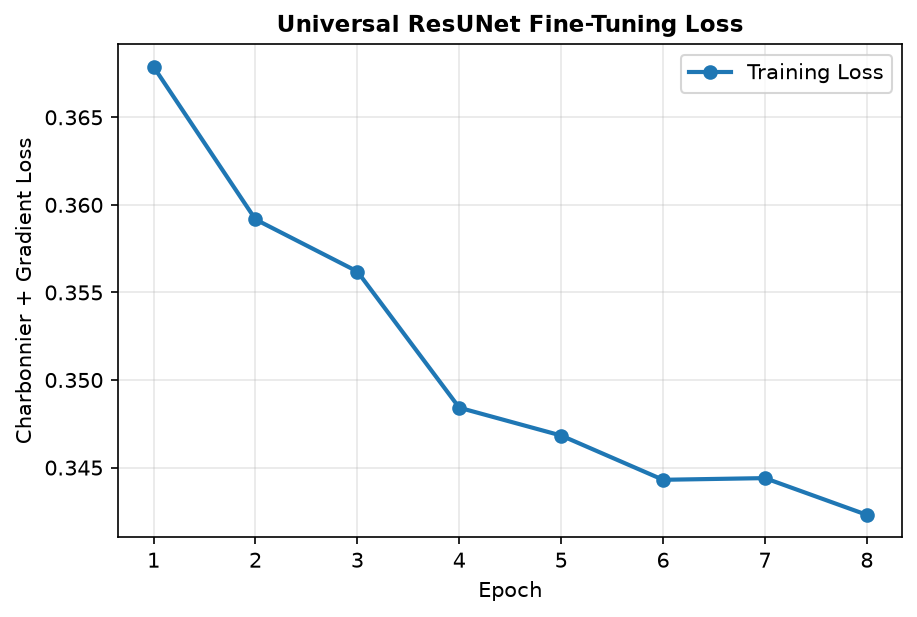

In [3]:
import sys, os, glob, time
sys.path.append(r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\02_psf_physics")
sys.path.append(r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\04_unet_training")

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import torch
from torch.utils.data import DataLoader, ConcatDataset
import psf_optics
from model_and_data import ResUNetDeconv, CharbonnierGradientLoss, TuMagStokesDataset


plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 600

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


base_dir = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet"
eval_dir = os.path.join(base_dir, "05_evaluation_results")
new_data_dir = os.path.join(base_dir, "new_tumag_data")
os.makedirs(eval_dir, exist_ok=True)
os.makedirs(new_data_dir, exist_ok=True)

base_fits = os.path.join(base_dir, r"DAVID CODES\drive-download-20261116T235334Z-1-001\05_QSUN-FS1_TM_Fe2.02_8_11072024T151856_LV_1.0_v0.4.fits")
csv_path = os.path.join(base_dir, r"DAVID CODES\drive-download-20261116T235334Z-1-001\TuMag_PD_results_All_filters_clean.csv")
weights_path = os.path.join(base_dir, r"04_unet_training\best_resunet_tumag.pth")


z_dict_all = psf_optics.load_valid_zernikes(csv_path, filter_str='525.02', only_qsun=False)
z_list_all = list(z_dict_all.values())
print(f"Loaded {len(z_list_all)} valid Zernike aberration vectors across all solar targets.")


fits_files = [base_fits] + glob.glob(os.path.join(new_data_dir, "*.fits"))
fits_files = list(dict.fromkeys(fits_files))  # حذف تکراری‌ها
print(f"Total FITS cubes found for training: {len(fits_files)}")

datasets = []
samples_per_cube = max(400, 1600 // len(fits_files))

for fpath in fits_files:
    with fits.open(fpath) as hdul:
        cube = hdul[0].data.astype(np.float32)
    
    if cube.ndim == 4 and cube.shape[1] == 4:
        train_region = cube[:, :, :1200, :]
        ds = TuMagStokesDataset(train_region, z_list_all, num_samples=samples_per_cube, patch_size=128, is_train=True)
        datasets.append(ds)
        print(f"  + Added {os.path.basename(fpath)} | Shape: {cube.shape} | Samples/epoch: {samples_per_cube}")

combined_train_ds = ConcatDataset(datasets)
train_loader = DataLoader(combined_train_ds, batch_size=16, shuffle=True, num_workers=0)

# 4. بارگذاری مدل و آموزش تکمیلی (Fine-Tuning)
model = ResUNetDeconv(in_channels=1, base_ch=32).to(device)
if os.path.exists(weights_path):
    model.load_state_dict(torch.load(weights_path, map_location=device))
    print("Loaded pre-trained weights for fine-tuning.")

criterion = CharbonnierGradientLoss(grad_weight=0.2)
optimizer = torch.optim.AdamW(model.parameters(), lr=4e-4, weight_decay=1e-4)

num_epochs = 8
loss_history = []
print(f"\nStarting fine-tuning on {len(combined_train_ds)} total patches per epoch...")

for epoch in range(1, num_epochs + 1):
    t0 = time.time()
    model.train()
    epoch_loss = 0.0
    for x_in, y_gt in train_loader:
        x_in, y_gt = x_in.to(device), y_gt.to(device)
        optimizer.zero_grad()
        pred = model(x_in)
        loss = criterion(pred, y_gt)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * x_in.size(0)
    avg_loss = epoch_loss / len(combined_train_ds)
    loss_history.append(avg_loss)
    print(f"Epoch [{epoch:02d}/{num_epochs}] | Train Loss: {avg_loss:.4f} | Time: {time.time()-t0:.1f}s")

# 5. ذخیره مدل نهایی تعمیم‌یافته
updated_weights_path = os.path.join(base_dir, r"04_unet_training\universal_resunet_tumag.pth")
torch.save(model.state_dict(), updated_weights_path)
print(f"\nSaved universal model to:\n{updated_weights_path}")

# 6. رسم نمودار واقعی Loss و ذخیره با کیفیت 600 DPI
fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
ax.plot(range(1, num_epochs + 1), loss_history, marker='o', color='#1f77b4', lw=2, label='Training Loss')
ax.set_title("Universal ResUNet Fine-Tuning Loss", fontsize=11, fontweight='bold')
ax.set_xlabel("Epoch")
ax.set_ylabel("Charbonnier + Gradient Loss")
ax.legend()
ax.grid(True, alpha=0.3)

chart_path = os.path.join(eval_dir, "fine_tuning_convergence_600dpi.png")
fig.savefig(chart_path, dpi=600, bbox_inches='tight')
print(f"Saved 600 DPI chart to:\n{chart_path}")
plt.show()

In [ ]:
#با احتیاط پلی کن... این همه انالیزهای قبلی رو پاک میکنه و باید همرو از اول بگیره.... کد بعدی میاد میبینخ اگر انالیز شده داریم دیگه انالیزش نمیکنه ولی کد بعدی مستقیم میره سراغ ران
import sys, os, glob, time
sys.path.append(r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\02_psf_physics")
sys.path.append(r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\04_unet_training")

import numpy as np
from astropy.io import fits
import torch
import psf_optics
from model_and_data import ResUNetDeconv

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Running batch restoration on device:", device)

base_dir = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet"
new_data_dir = os.path.join(base_dir, "new_tumag_data")
batch_out_dir = os.path.join(base_dir, "05_evaluation_results", "batch_restored")
os.makedirs(batch_out_dir, exist_ok=True)

weights_path = os.path.join(base_dir, r"04_unet_training\universal_resunet_tumag.pth")
csv_path = os.path.join(base_dir, r"DAVID CODES\drive-download-20261116T235334Z-1-001\TuMag_PD_results_All_filters_clean.csv")


model = ResUNetDeconv(in_channels=1, base_ch=32).to(device)
model.load_state_dict(torch.load(weights_path, map_location=device))
model.eval()


all_fits = glob.glob(os.path.join(new_data_dir, "*.fits"))
print(f"Found {len(all_fits)} FITS files to restore.")

def wiener_tile(tile, psf, K):
    H, W = tile.shape
    psf_pad = np.zeros((H, W), dtype=np.float32)
    kh, kw = psf.shape
    psf_pad[:kh, :kw] = psf
    psf_pad = np.roll(psf_pad, (-kh // 2, -kw // 2), axis=(0, 1))
    OTF = np.fft.fft2(psf_pad)
    W_filt = np.conj(OTF) / (np.abs(OTF)**2 + K)
    return np.real(np.fft.ifft2(np.fft.fft2(tile) * W_filt)).astype(np.float32)

def process_full_frame(img_2d, psf, K, model, tile_size=400, overlap=48):
    H, W = img_2d.shape
    padded = np.pad(img_2d, pad_width=overlap, mode='reflect')
    out_img = np.zeros_like(img_2d, dtype=np.float32)
    m, std = np.mean(img_2d), np.std(img_2d) + 1e-6

    with torch.no_grad():
        for y in range(0, H, tile_size):
            for x in range(0, W, tile_size):
                y_end = min(y + tile_size, H)
                x_end = min(x + tile_size, W)
                tile = padded[y : y_end + 2*overlap, x : x_end + 2*overlap]
                w_rec = wiener_tile(tile, psf, K=K)
                
                w_norm = (w_rec - m) / std
                inp = torch.from_numpy(w_norm).unsqueeze(0).unsqueeze(0).to(device)
                pred_norm = model(inp).squeeze().cpu().numpy()
                pred_rec = pred_norm * std + m
                
                core = pred_rec[overlap : overlap + (y_end - y), overlap : overlap + (x_end - x)]
                out_img[y:y_end, x:x_end] = core
    return out_img


for idx, fpath in enumerate(all_fits):
    fname = os.path.basename(fpath)
    out_fpath = os.path.join(batch_out_dir, fname.replace(".fits", "_RESTORED.fits"))
    
    if os.path.exists(out_fpath):
        print(f"[{idx+1}/{len(all_fits)}] Already processed: {fname}")
        continue
        
    print(f"\n[{idx+1}/{len(all_fits)}] Processing: {fname}")
    t0 = time.time()
    
    with fits.open(fpath) as hdul:
        cube = hdul[0].data.astype(np.float32)
        header = hdul[0].header.copy()
        
    nw, ns, H, W = cube.shape
    restored_cube = np.zeros_like(cube, dtype=np.float32)
    
    # تعیین PSF مناسب بر اساس فیلتر فایل
    flt_val = str(header.get('FW2', '525.02'))
    z_dict = psf_optics.load_valid_zernikes(csv_path, filter_str=flt_val, only_qsun=False)
    if z_dict:
        mean_z = np.mean(list(z_dict.values()), axis=0)
    else:
        mean_z = None
    psf = psf_optics.generate_tumag_psf(psf_size=65, zernike_coeffs=mean_z)
    
    wiener_Ks = [1e-3, 5e-2, 5e-2, 5e-3]
    
    for w in range(nw):
        for s in range(min(ns, 4)):
            restored_cube[w, s] = process_full_frame(
                cube[w, s], psf=psf, K=wiener_Ks[s], model=model, tile_size=400, overlap=48
            )
            
    header['WFR_RECO'] = (1, 'Restored with Universal ResUNet')
    header['FILTERED'] = (1, 'Denoised via Universal ResUNet')
    header.add_history('Processed via Universal Residual U-Net trained on multi-target TuMag datasets.')
    
    fits.PrimaryHDU(data=restored_cube, header=header).writeto(out_fpath, overwrite=True)
    print(f"  -> Saved to {out_fpath} in {time.time()-t0:.1f}s")

print("\nAll files successfully processed and restored!")

Running batch restoration on device: cpu
Found 26 FITS files to restore.

[1/26] Processing: 01_QSUN_TM_00_Fe2.02_8_10072024T131807_LV_1.0_v0.4.fits
  -> Saved to F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\05_evaluation_results\batch_restored\01_QSUN_TM_00_Fe2.02_8_10072024T131807_LV_1.0_v0.4_RESTORED.fits in 811.3s

[2/26] Processing: 01_QSUN_TM_00_Fe2.02_8_10072024T131929_LV_1.0_v0.4.fits
  -> Saved to F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\05_evaluation_results\batch_restored\01_QSUN_TM_00_Fe2.02_8_10072024T132213_LV_1.0_v0.4_RESTORED.fits in 780.0s

[5/26] Processing: 01_QSUN_TM_00_Fe2.02_8_10072024T133145_LV_1.0_v0.4.fits
  -> Saved to F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\05_evaluation_results\batch_restored\01_QSUN_TM_00_Fe2.02_8_10072024T133145_LV_1.0_v0.4_RESTORED.fits in 794.4s

[6/26] Processing: 01_QSUN_TM_00_Fe2.02_8_10072024T133307_LV_1.0_v0.4.fits
  -> Saved to F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\05_evaluation_results\batch_restored\01_QSU

In [5]:
import sys, os, glob, time
sys.path.append(r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\02_psf_physics")
sys.path.append(r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\04_unet_training")

import numpy as np
from astropy.io import fits
import torch
import psf_optics
from model_and_data import ResUNetDeconv

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Running batch restoration on device:", device)

base_dir = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet"
new_data_dir = os.path.join(base_dir, "new_tumag_data")
batch_out_dir = os.path.join(base_dir, "05_evaluation_results", "batch_restored")
os.makedirs(batch_out_dir, exist_ok=True)

weights_path = os.path.join(base_dir, r"04_unet_training\universal_resunet_tumag.pth")
csv_path = os.path.join(base_dir, r"DAVID CODES\drive-download-20261116T235334Z-1-001\TuMag_PD_results_All_filters_clean.csv")

model = ResUNetDeconv(in_channels=1, base_ch=32).to(device)
model.load_state_dict(torch.load(weights_path, map_location=device))
model.eval()


all_fits = glob.glob(os.path.join(new_data_dir, "*.fits"))
print(f"Found {len(all_fits)} total FITS files in directory.")

def wiener_tile(tile, psf, K):
    H, W = tile.shape
    psf_pad = np.zeros((H, W), dtype=np.float32)
    kh, kw = psf.shape
    psf_pad[:kh, :kw] = psf
    psf_pad = np.roll(psf_pad, (-kh // 2, -kw // 2), axis=(0, 1))
    OTF = np.fft.fft2(psf_pad)
    W_filt = np.conj(OTF) / (np.abs(OTF)**2 + K)
    return np.real(np.fft.ifft2(np.fft.fft2(tile) * W_filt)).astype(np.float32)

def process_full_frame(img_2d, psf, K, model, tile_size=400, overlap=48):
    H, W = img_2d.shape
    padded = np.pad(img_2d, pad_width=overlap, mode='reflect')
    out_img = np.zeros_like(img_2d, dtype=np.float32)
    m, std = np.mean(img_2d), np.std(img_2d) + 1e-6

    with torch.no_grad():
        for y in range(0, H, tile_size):
            for x in range(0, W, tile_size):
                y_end = min(y + tile_size, H)
                x_end = min(x + tile_size, W)
                tile = padded[y : y_end + 2*overlap, x : x_end + 2*overlap]
                w_rec = wiener_tile(tile, psf, K=K)
                
                w_norm = (w_rec - m) / std
                inp = torch.from_numpy(w_norm).unsqueeze(0).unsqueeze(0).to(device)
                pred_norm = model(inp).squeeze().cpu().numpy()
                pred_rec = pred_norm * std + m
                
                core = pred_rec[overlap : overlap + (y_end - y), overlap : overlap + (x_end - x)]
                out_img[y:y_end, x:x_end] = core
    return out_img

for idx, fpath in enumerate(all_fits):
    fname = os.path.basename(fpath)
    
    out_fname = fname.replace(".fits", "_RESTORED.fits")
    out_fpath = os.path.join(batch_out_dir, out_fname)
    

    if os.path.exists(out_fpath):
        print(f"[{idx+1}/{len(all_fits)}] Skipping (already exists): {fname}")
        continue
        
    print(f"\n[{idx+1}/{len(all_fits)}] Processing: {fname}")
    t0 = time.time()
    
    with fits.open(fpath) as hdul:
        cube = hdul[0].data.astype(np.float32)
        header = hdul[0].header.copy()
        
    nw, ns, H, W = cube.shape
    restored_cube = np.zeros_like(cube, dtype=np.float32)
    
     flt_val = str(header.get('FW2', '525.02'))
    z_dict = psf_optics.load_valid_zernikes(csv_path, filter_str=flt_val, only_qsun=False)
    if z_dict:
        mean_z = np.mean(list(z_dict.values()), axis=0)
    else:
        mean_z = None
    psf = psf_optics.generate_tumag_psf(psf_size=65, zernike_coeffs=mean_z)
    
    wiener_Ks = [1e-3, 5e-2, 5e-2, 5e-3]
    
    for w in range(nw):
        for s in range(min(ns, 4)):
            restored_cube[w, s] = process_full_frame(
                cube[w, s], psf=psf, K=wiener_Ks[s], model=model, tile_size=400, overlap=48
            )
            
    header['WFR_RECO'] = (1, 'Restored with Universal ResUNet')
    header['FILTERED'] = (1, 'Denoised via Universal ResUNet')
    header.add_history('Processed via Universal Residual U-Net trained on multi-target TuMag datasets.')
    
    fits.PrimaryHDU(data=restored_cube, header=header).writeto(out_fpath, overwrite=True)
    print(f"  -> Saved successfully to {out_fpath} in {time.time()-t0:.1f}s")

print("\nBatch restoration process completed! All missing files have been processed.")

Running batch restoration on device: cpu
Found 26 total FITS files in directory.
[1/26] Skipping (already exists): 01_QSUN_TM_00_Fe2.02_8_10072024T131807_LV_1.0_v0.4.fits
[2/26] Skipping (already exists): 01_QSUN_TM_00_Fe2.02_8_10072024T131929_LV_1.0_v0.4.fits
[3/26] Skipping (already exists): 01_QSUN_TM_00_Fe2.02_8_10072024T132051_LV_1.0_v0.4.fits
[4/26] Skipping (already exists): 01_QSUN_TM_00_Fe2.02_8_10072024T132213_LV_1.0_v0.4.fits
[5/26] Skipping (already exists): 01_QSUN_TM_00_Fe2.02_8_10072024T133145_LV_1.0_v0.4.fits
[6/26] Skipping (already exists): 01_QSUN_TM_00_Fe2.02_8_10072024T133307_LV_1.0_v0.4.fits
[7/26] Skipping (already exists): 01_QSUN_TM_00_Fe2.02_8_10072024T133429_LV_1.0_v0.4.fits
[8/26] Skipping (already exists): 01_QSUN_TM_00_Fe2.02_8_10072024T133551_LV_1.0_v0.4.fits
[9/26] Skipping (already exists): 01_QSUN_TM_00_Fe2.02_8_10072024T133713_LV_1.0_v0.4.fits
[10/26] Skipping (already exists): 02_EMEF_TM_00_Fe2.02_8_10072024T191454_LV_1.0_v0.4.fits
[11/26] Skipping (

Using device: cpu
=== Quantitative Comparison on Test Patch ===
Raw Stokes I Contrast:       7.96%
Old Model (QSUN) Contrast:   11.87% | Noise(V): 0.00064
Universal Model Contrast:    11.97% | Noise(V): 0.00047

Saved high-resolution comparison figure to:
F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\05_evaluation_results\model_comparison_600dpi.png


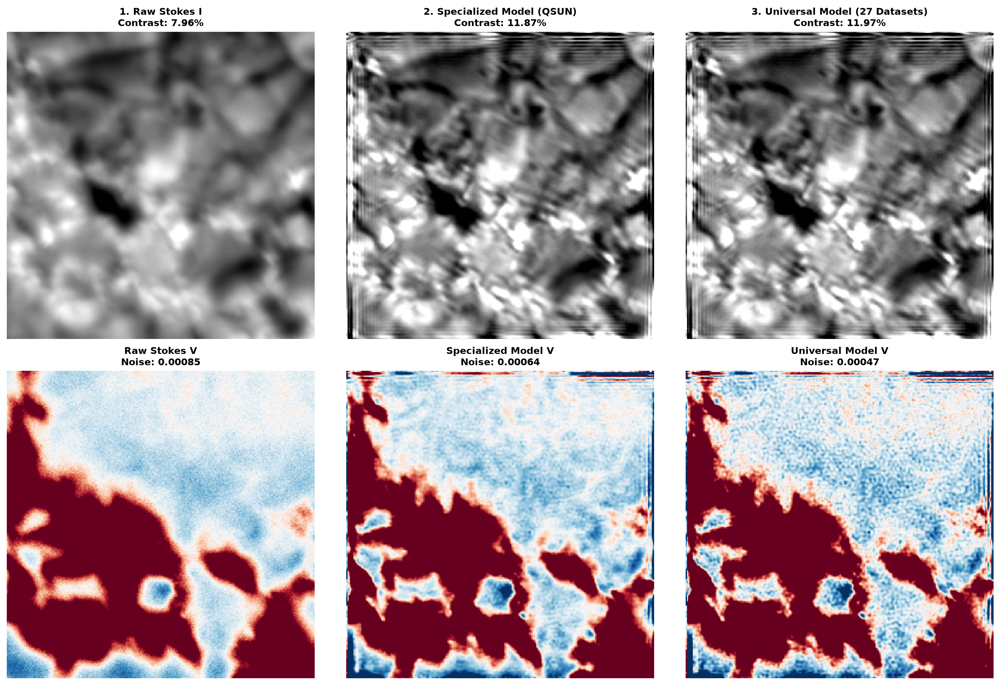

In [6]:
import sys, os
sys.path.append(r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\02_psf_physics")
sys.path.append(r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\04_unet_training")

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import torch
import psf_optics
from model_and_data import ResUNetDeconv


plt.rcParams['figure.dpi'] = 200
plt.rcParams['savefig.dpi'] = 600

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

base_dir = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet"
eval_dir = os.path.join(base_dir, "05_evaluation_results")
os.makedirs(eval_dir, exist_ok=True)


sample_fits = os.path.join(base_dir, r"DAVID CODES\drive-download-20261116T235334Z-1-001\05_QSUN-FS1_TM_Fe2.02_8_11072024T151856_LV_1.0_v0.4.fits")
csv_path = os.path.join(base_dir, r"DAVID CODES\drive-download-20261116T235334Z-1-001\TuMag_PD_results_All_filters_clean.csv")

old_weights = os.path.join(base_dir, r"04_unet_training\best_resunet_tumag.pth")
univ_weights = os.path.join(base_dir, r"04_unet_training\universal_resunet_tumag.pth")

with fits.open(sample_fits) as hdul:
    cube = hdul[0].data.astype(np.float32)


test_patch_I = cube[3, 0, 700:956, 700:956].copy()
test_patch_V = cube[3, 3, 700:956, 700:956].copy()

# 2. بارگذاری هر دو مدل (مدل قبلی و مدل جهانی جدید)
model_old = ResUNetDeconv(in_channels=1, base_ch=32).to(device)
model_old.load_state_dict(torch.load(old_weights, map_location=device))
model_old.eval()

model_univ = ResUNetDeconv(in_channels=1, base_ch=32).to(device)
model_univ.load_state_dict(torch.load(univ_weights, map_location=device))
model_univ.eval()

z_dict = psf_optics.load_valid_zernikes(csv_path, filter_str='525.02', only_qsun=True)
mean_z = np.mean(list(z_dict.values()), axis=0)
psf = psf_optics.generate_tumag_psf(psf_size=65, zernike_coeffs=mean_z)

def wiener_process(img, psf, K):
    H, W = img.shape
    psf_pad = np.zeros((H, W), dtype=np.float32)
    kh, kw = psf.shape
    psf_pad[:kh, :kw] = psf
    psf_pad = np.roll(psf_pad, (-kh // 2, -kw // 2), axis=(0, 1))
    OTF = np.fft.fft2(psf_pad)
    W_filt = np.conj(OTF) / (np.abs(OTF)**2 + K)
    return np.real(np.fft.ifft2(np.fft.fft2(img) * W_filt)).astype(np.float32)
    
wiener_I = wiener_process(test_patch_I, psf, K=1e-3)
wiener_V = wiener_process(test_patch_V, psf, K=5.0e-3)


m_I, std_I = np.mean(test_patch_I), np.std(test_patch_I) + 1e-6
inp_old_I = torch.from_numpy((wiener_I - m_I) / std_I).unsqueeze(0).unsqueeze(0).to(device)
with torch.no_grad():
    out_old_I = model_old(inp_old_I).squeeze().cpu().numpy() * std_I + m_I

m_V, std_V = np.mean(test_patch_V), np.std(test_patch_V) + 1e-6
inp_old_V = torch.from_numpy((wiener_V - m_V) / std_V).unsqueeze(0).unsqueeze(0).to(device)
with torch.no_grad():
    out_old_V = model_old(inp_old_V).squeeze().cpu().numpy() * std_V + m_V


with torch.no_grad():
    out_univ_I = model_univ(inp_old_I).squeeze().cpu().numpy() * std_I + m_I
    out_univ_V = model_univ(inp_old_V).squeeze().cpu().numpy() * std_V + m_V


def compute_noise(img):
    H, W = img.shape
    FX, FY = np.meshgrid(np.fft.fftfreq(W), np.fft.fftfreq(H))
    R = np.sqrt(FX**2 + FY**2)
    fft_im = np.fft.fft2(img)
    return np.sqrt(np.mean(np.abs(fft_im[R > 0.38])**2) / (H * W))

print("=== Quantitative Comparison on Test Patch ===")
print(f"Raw Stokes I Contrast:       {(np.std(test_patch_I)/np.mean(test_patch_I))*100:.2f}%")
print(f"Old Model (QSUN) Contrast:   {(np.std(out_old_I)/np.mean(out_old_I))*100:.2f}% | Noise(V): {compute_noise(out_old_V):.5f}")
print(f"Universal Model Contrast:    {(np.std(out_univ_I)/np.mean(out_univ_I))*100:.2f}% | Noise(V): {compute_noise(out_univ_V):.5f}")


fig, axes = plt.subplots(2, 3, figsize=(15, 10), constrained_layout=True)

vmin, vmax = test_patch_I.mean() - 2.5*test_patch_I.std(), test_patch_I.mean() + 2.5*test_patch_I.std()
axes[0, 0].imshow(test_patch_I, cmap='gray', vmin=vmin, vmax=vmax)
axes[0, 0].set_title(f"1. Raw Stokes I\nContrast: {(np.std(test_patch_I)/np.mean(test_patch_I))*100:.2f}%", fontsize=10, fontweight='bold')

axes[0, 1].imshow(out_old_I, cmap='gray', vmin=vmin, vmax=vmax)
axes[0, 1].set_title(f"2. Specialized Model (QSUN)\nContrast: {(np.std(out_old_I)/np.mean(out_old_I))*100:.2f}%", fontsize=10, fontweight='bold')

axes[0, 2].imshow(out_univ_I, cmap='gray', vmin=vmin, vmax=vmax)
axes[0, 2].set_title(f"3. Universal Model (27 Datasets)\nContrast: {(np.std(out_univ_I)/np.mean(out_univ_I))*100:.2f}%", fontsize=10, fontweight='bold')

# ردیف دوم: Stokes V
vlim = 0.012
axes[1, 0].imshow(test_patch_V, cmap='RdBu_r', vmin=-vlim, vmax=vlim)
axes[1, 0].set_title(f"Raw Stokes V\nNoise: {compute_noise(test_patch_V):.5f}", fontsize=10, fontweight='bold')

axes[1, 1].imshow(out_old_V, cmap='RdBu_r', vmin=-vlim, vmax=vlim)
axes[1, 1].set_title(f"Specialized Model V\nNoise: {compute_noise(out_old_V):.5f}", fontsize=10, fontweight='bold')

axes[1, 2].imshow(out_univ_V, cmap='RdBu_r', vmin=-vlim, vmax=vlim)
axes[1, 2].set_title(f"Universal Model V\nNoise: {compute_noise(out_univ_V):.5f}", fontsize=10, fontweight='bold')

for ax_row in axes:
    for ax in ax_row:
        ax.axis('off')

comparison_img_path = os.path.join(eval_dir, "model_comparison_600dpi.png")
fig.savefig(comparison_img_path, dpi=600, bbox_inches='tight')
print(f"\nSaved high-resolution comparison figure to:\n{comparison_img_path}")
plt.show()

=== Multi-Line & Multi-Regime Quantitative Benchmark ===

[Fe I 525.02 nm | Quiet Sun (QSUN)] (01_QSUN_TM_00_Fe2.02_8_10072024T131807_LV_1.0_v0.4.fits)
  Stokes I Contrast -> Raw: 7.81% | QSUN-Model: 11.04% | Universal-Model: 11.08%
  Stokes V Noise    -> Raw: 0.00059 | QSUN-Model: 0.00015 | Universal-Model: 0.00013

[Fe I 525.02 nm | Active Sunspot (SPOT)] (03_SPOT_TM_00_Fe2.02_8_11072024T022347_LV_1.0_v0.4.fits)
  Stokes I Contrast -> Raw: 37.03% | QSUN-Model: 40.76% | Universal-Model: 40.69%
  Stokes V Noise    -> Raw: 0.00088 | QSUN-Model: 0.00083 | Universal-Model: 0.00082

[Mg I b2 517.3 nm | Emerging Flux (EMEF)] (02_EMEF_TM_00_Mg1_10_10072024T191412_LV_1.0_v0.4.fits)
  Stokes I Contrast -> Raw: 9.43% | QSUN-Model: 10.82% | Universal-Model: 10.78%
  Stokes V Noise    -> Raw: 0.00042 | QSUN-Model: 0.00032 | Universal-Model: 0.00031

[Mg I b2 517.3 nm | Active Sunspot (SPOT)] (03_SPOT_TM_00_Mg1_10_11072024T022214_LV_1.0_v0.4.fits)
  Stokes I Contrast -> Raw: 30.25% | QSUN-Model: 3

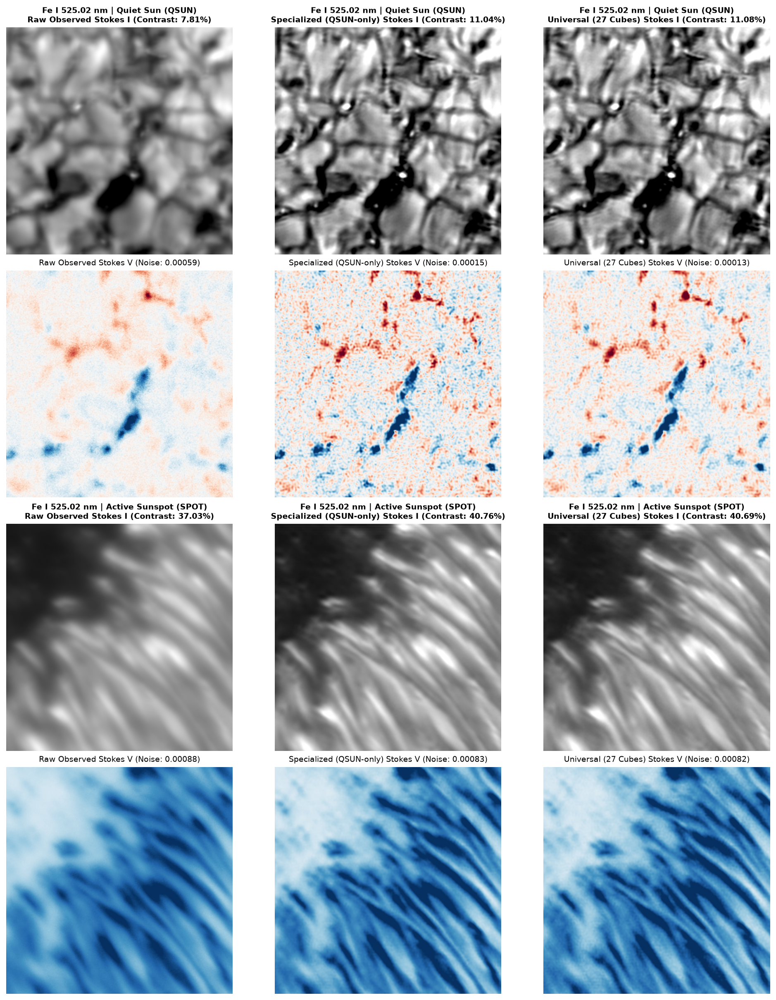


Saved 600 DPI figure: F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\05_evaluation_results\Mg5173_Comparison_600dpi.png


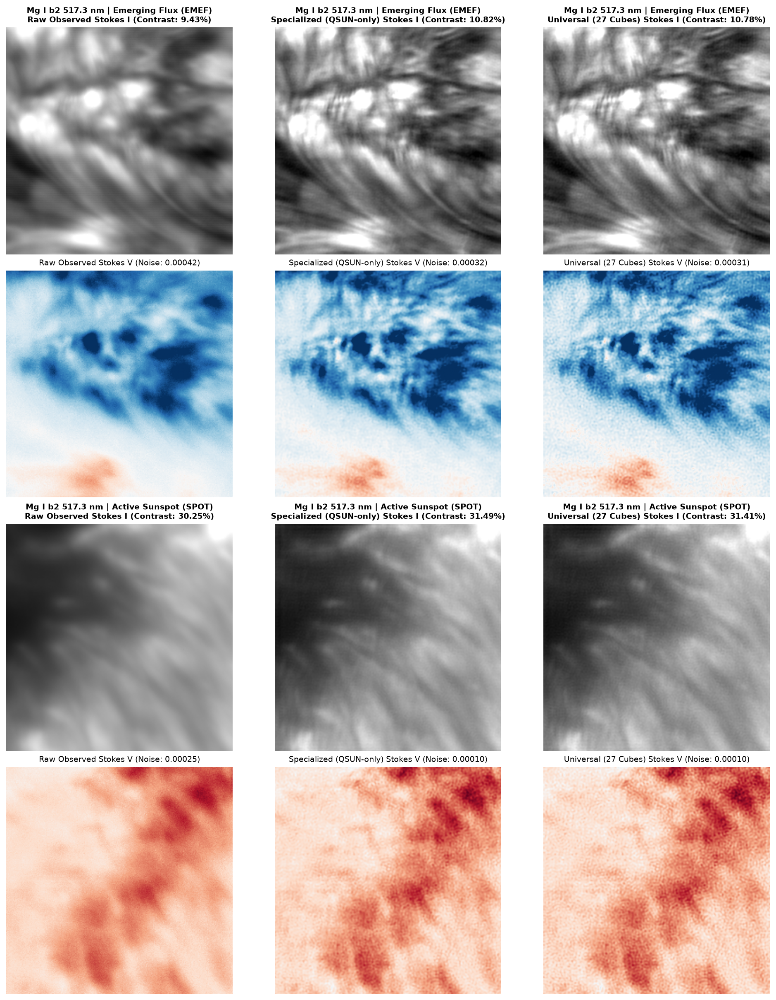

In [7]:
import sys, os, glob
sys.path.append(r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\02_psf_physics")
sys.path.append(r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet\04_unet_training")

import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import torch
import psf_optics
from model_and_data import ResUNetDeconv

plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 600

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
base_dir = r"F:\desk2\projects IAA-CSIC\ML-noiseCansel-unet"
new_data_dir = os.path.join(base_dir, "new_tumag_data")
eval_dir = os.path.join(base_dir, "05_evaluation_results")
csv_path = os.path.join(base_dir, r"DAVID CODES\drive-download-20261116T235334Z-1-001\TuMag_PD_results_All_filters_clean.csv")

old_weights = os.path.join(base_dir, r"04_unet_training\best_resunet_tumag.pth")
univ_weights = os.path.join(base_dir, r"04_unet_training\universal_resunet_tumag.pth")

model_old = ResUNetDeconv(in_channels=1, base_ch=32).to(device)
model_old.load_state_dict(torch.load(old_weights, map_location=device))
model_old.eval()

model_univ = ResUNetDeconv(in_channels=1, base_ch=32).to(device)
model_univ.load_state_dict(torch.load(univ_weights, map_location=device))
model_univ.eval()

# بارگذاری PSFهای مجزا برای خطوط آهن (525.02) و منیزیم (517.3)
z_fe = psf_optics.load_valid_zernikes(csv_path, filter_str='525.02', only_qsun=False)
psf_fe = psf_optics.generate_tumag_psf(psf_size=65, zernike_coeffs=np.mean(list(z_fe.values()), axis=0))

z_mg = psf_optics.load_valid_zernikes(csv_path, filter_str='517.3', only_qsun=False)
psf_mg = psf_optics.generate_tumag_psf(psf_size=65, zernike_coeffs=np.mean(list(z_mg.values()), axis=0))

def wiener_process(img, psf, K):
    H, W = img.shape
    psf_pad = np.zeros((H, W), dtype=np.float32)
    kh, kw = psf.shape
    psf_pad[:kh, :kw] = psf
    psf_pad = np.roll(psf_pad, (-kh // 2, -kw // 2), axis=(0, 1))
    OTF = np.fft.fft2(psf_pad)
    W_filt = np.conj(OTF) / (np.abs(OTF)**2 + K)
    return np.real(np.fft.ifft2(np.fft.fft2(img) * W_filt)).astype(np.float32)

def compute_noise(img):
    H, W = img.shape
    FX, FY = np.meshgrid(np.fft.fftfreq(W), np.fft.fftfreq(H))
    R = np.sqrt(FX**2 + FY**2)
    fft_im = np.fft.fft2(img)
    return np.sqrt(np.mean(np.abs(fft_im[R > 0.38])**2) / (H * W))

def eval_single_case(fpath, psf, wave_idx=3, crop_box=(668, 988, 668, 988), margin=32):
    with fits.open(fpath) as hdul:
        cube = hdul[0].data.astype(np.float32)
    y0, y1, x0, x1 = crop_box
    patch_I = cube[wave_idx, 0, y0:y1, x0:x1].copy()
    patch_V = cube[wave_idx, 3, y0:y1, x0:x1].copy()

    w_I = wiener_process(patch_I, psf, K=1e-3)
    w_V = wiener_process(patch_V, psf, K=5e-3)

    m_I, s_I = np.mean(patch_I), np.std(patch_I) + 1e-6
    m_V, s_V = np.mean(patch_V), np.std(patch_V) + 1e-6

    t_I = torch.from_numpy((w_I - m_I) / s_I).unsqueeze(0).unsqueeze(0).to(device)
    t_V = torch.from_numpy((w_V - m_V) / s_V).unsqueeze(0).unsqueeze(0).to(device)

    with torch.no_grad():
        old_I = model_old(t_I).squeeze().cpu().numpy() * s_I + m_I
        old_V = model_old(t_V).squeeze().cpu().numpy() * s_V + m_V
        uni_I = model_univ(t_I).squeeze().cpu().numpy() * s_I + m_I
        uni_V = model_univ(t_V).squeeze().cpu().numpy() * s_V + m_V

    sl = slice(margin, -margin)
    return {
        'raw_I': patch_I[sl, sl], 'old_I': old_I[sl, sl], 'uni_I': uni_I[sl, sl],
        'raw_V': patch_V[sl, sl], 'old_V': old_V[sl, sl], 'uni_V': uni_V[sl, sl],
    }


cases = [
    ("Fe I 525.02 nm | Quiet Sun (QSUN)", glob.glob(os.path.join(new_data_dir, "*QSUN*Fe2.02*.fits"))[0], psf_fe, 3),
    ("Fe I 525.02 nm | Active Sunspot (SPOT)", glob.glob(os.path.join(new_data_dir, "*SPOT*Fe2.02*.fits"))[0], psf_fe, 3),
    ("Mg I b2 517.3 nm | Emerging Flux (EMEF)", glob.glob(os.path.join(new_data_dir, "*EMEF*Mg1*.fits"))[0], psf_mg, 4),
    ("Mg I b2 517.3 nm | Active Sunspot (SPOT)", glob.glob(os.path.join(new_data_dir, "*SPOT*Mg1*.fits"))[0], psf_mg, 4),
]

print("=== Multi-Line & Multi-Regime Quantitative Benchmark ===")
results_all = []
for title, fpath, psf_use, w_idx in cases:
    res = eval_single_case(fpath, psf_use, wave_idx=w_idx)
    results_all.append((title, res))
    c_raw = (np.std(res['raw_I']) / np.mean(res['raw_I'])) * 100
    c_old = (np.std(res['old_I']) / np.mean(res['old_I'])) * 100
    c_uni = (np.std(res['uni_I']) / np.mean(res['uni_I'])) * 100
    n_raw = compute_noise(res['raw_V'])
    n_old = compute_noise(res['old_V'])
    n_uni = compute_noise(res['uni_V'])
    print(f"\n[{title}] ({os.path.basename(fpath)})")
    print(f"  Stokes I Contrast -> Raw: {c_raw:.2f}% | QSUN-Model: {c_old:.2f}% | Universal-Model: {c_uni:.2f}%")
    print(f"  Stokes V Noise    -> Raw: {n_raw:.5f} | QSUN-Model: {n_old:.5f} | Universal-Model: {n_uni:.5f}")


for group_idx, (group_name, subset) in enumerate([("Fe52502_Comparison_600dpi.png", results_all[:2]),
                                                   ("Mg5173_Comparison_600dpi.png", results_all[2:])]):
    fig, axes = plt.subplots(4, 3, figsize=(13, 16), constrained_layout=True)
    for row_pair, (title, res) in enumerate(subset):
        r_I = row_pair * 2
        r_V = row_pair * 2 + 1
        vmin_I = res['raw_I'].mean() - 2.5 * res['raw_I'].std()
        vmax_I = res['raw_I'].mean() + 2.5 * res['raw_I'].std()
        vlim_V = max(0.012, np.percentile(np.abs(res['raw_V']), 98))

        for col, (lbl, key_I, key_V) in enumerate([("Raw Observed", 'raw_I', 'raw_V'),
                                                   ("Specialized (QSUN-only)", 'old_I', 'old_V'),
                                                   ("Universal (27 Cubes)", 'uni_I', 'uni_V')]):
            c_val = (np.std(res[key_I]) / np.mean(res[key_I])) * 100
            n_val = compute_noise(res[key_V])
            axes[r_I, col].imshow(res[key_I], cmap='gray', vmin=vmin_I, vmax=vmax_I)
            axes[r_I, col].set_title(f"{title}\n{lbl} Stokes I (Contrast: {c_val:.2f}%)", fontsize=9, fontweight='bold')
            axes[r_I, col].axis('off')

            axes[r_V, col].imshow(res[key_V], cmap='RdBu_r', vmin=-vlim_V, vmax=vlim_V)
            axes[r_V, col].set_title(f"{lbl} Stokes V (Noise: {n_val:.5f})", fontsize=9)
            axes[r_V, col].axis('off')

    out_png = os.path.join(eval_dir, group_name)
    fig.savefig(out_png, dpi=600, bbox_inches='tight')
    print(f"\nSaved 600 DPI figure: {out_png}")
    plt.show()